# EDA - sweet.tv TV program recommender

## Environment

In [1]:
import os
import sys
import gc
import time
import platform
import warnings
import resource
import importlib.metadata as md
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import pyarrow.parquet as pq
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

print("Python:", sys.version.split()[0])
for package_name in [
    "numpy", "pandas", "pyarrow", "matplotlib", "seaborn",
    "psutil", "nbformat", "nbconvert", "jupyter_core",
]:
    try:
        print(f"{package_name}: {md.version(package_name)}")
    except Exception as exc:
        print(f"{package_name}: unavailable ({exc})")
print("OS:", platform.platform())
print("CPU logical:", psutil.cpu_count(logical=True), "CPU physical:", psutil.cpu_count(logical=False))
print("RAM total GB:", round(psutil.virtual_memory().total / 1e9, 2))
print("Matplotlib backend:", matplotlib.get_backend())

Python: 3.12.3
numpy: 2.5.4
pandas: 3.0.6
pyarrow: 26.0.0
matplotlib: 3.11.2
seaborn: 0.13.2
psutil: 7.2.2
nbformat: 5.11.1
nbconvert: 7.17.2
jupyter_core: 5.9.1
OS: Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.39
CPU logical: 4 CPU physical: 2
RAM total GB: 4.01
Matplotlib backend: module://matplotlib_inline.backend_inline


In [2]:
import sys
from pathlib import Path

_helper_project_root = Path.cwd()
for _candidate in [Path.cwd(), *Path.cwd().parents]:
    if (_candidate / "src" / "data.py").exists():
        _helper_project_root = _candidate
        break
if str(_helper_project_root) not in sys.path:
    sys.path.insert(0, str(_helper_project_root))

from src.data import (
    RATIO_THRESHOLD,
    airings_exceeding_duration,
    build_aggregated_items,
    build_airing_table,
    build_overlap_pairs,
    items_for_weeks,
    items_for_weeks_with_ratio,
    merge_overlapping_views,
    to_epoch_seconds,
)

print("Imported reusable helpers from src/data.py")

Imported reusable helpers from src/data.py


## Configuration

In [3]:
SEED = 42

PROJECT_ROOT = Path.cwd()
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "data_par" / "raw").exists():
        PROJECT_ROOT = candidate
        break

RAW_DIR = PROJECT_ROOT / "data_par" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "eda"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

STYLE = "whitegrid"
DPI = 150
FIG_SIZE = (10, 6)
DISPLAY_MAX_ROWS = 20
DISPLAY_MAX_COLS = 30
DISPLAY_MAX_COLWIDTH = 90

sns.set_theme(style=STYLE, context="notebook")
plt.rcParams.update({
    "figure.figsize": FIG_SIZE,
    "figure.dpi": DPI,
    "savefig.dpi": DPI,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.unicode_minus": False,
})

EXPECTED_VIEW_COLUMNS = [
    "user_id", "vsetv_id", "start_time", "stop_time", "duraton",
]
EXPECTED_SCHEDULE_COLUMNS = [
    "channel_id", "channel_title", "start_time", "duration",
    "tv_show_title", "tv_show_id", "tv_show_category",
    "tv_show_genre_1", "tv_show_genre_2", "tv_show_genre_3",
    "year_of_production", "director", "actors",
]

INTERACTION_THRESHOLDS = {
    "any_overlap_gt_0s": {"kind": "overlap_s", "value": 0.0, "strict": True},
    "overlap_ge_30s": {"kind": "overlap_s", "value": 30.0, "strict": False},
    "overlap_ge_60s": {"kind": "overlap_s", "value": 60.0, "strict": False},
    "overlap_over_view_duration_ge_0.3": {"kind": "view_ratio", "value": 0.3, "strict": False},
    "overlap_over_view_duration_ge_0.5": {"kind": "view_ratio", "value": 0.5, "strict": False},
    "overlap_over_show_duration_ge_0.3": {"kind": "show_ratio", "value": 0.3, "strict": False},
    "overlap_over_show_duration_ge_0.5": {"kind": "show_ratio", "value": 0.5, "strict": False},
    "overlap_over_show_duration_ge_0.8_candidate": {"kind": "show_ratio", "value": RATIO_THRESHOLD, "strict": False},
}

parquet_files = sorted(RAW_DIR.glob("*.parquet"))
schema_names = {path: pq.ParquetFile(path).schema_arrow.names for path in parquet_files}

view_candidates = [
    path for path in parquet_files
    if {"user_id", "vsetv_id"}.issubset(set(schema_names[path]))
]
schedule_candidates = [
    path for path in parquet_files
    if {"channel_id", "tv_show_id", "start_time", "duration"}.issubset(set(schema_names[path]))
]

if not view_candidates:
    raise FileNotFoundError("No parquet file with user_id and vsetv_id was found")
if not schedule_candidates:
    raise FileNotFoundError("No parquet schedule file was found")

VIEW_LOG_PATH = view_candidates[0]

schedule_ranges = {}
for path in schedule_candidates:
    time_values = pd.read_parquet(path, columns=["start_time"])["start_time"]
    parsed = pd.to_datetime(time_values, format="%d.%m.%Y %H:%M:%S", errors="coerce").astype("datetime64[ns]")
    schedule_ranges[path] = (parsed.min(), parsed.max())
    del time_values, parsed
    gc.collect()

schedule_candidates = sorted(schedule_candidates, key=lambda p: schedule_ranges[p][0])
if len(schedule_candidates) >= 2:
    TRAIN_SCHEDULE_PATHS = schedule_candidates[:-1]
    TEST_SCHEDULE_PATH = schedule_candidates[-1]
else:
    TRAIN_SCHEDULE_PATHS = schedule_candidates
    TEST_SCHEDULE_PATH = schedule_candidates[-1]

SCHEDULE_PATHS = {}
for idx, path in enumerate(TRAIN_SCHEDULE_PATHS, start=1):
    SCHEDULE_PATHS[f"train_schedule_{idx}"] = path
SCHEDULE_PATHS["test_schedule"] = TEST_SCHEDULE_PATH
TRAIN_SCHEDULE_ROLES = [role for role in SCHEDULE_PATHS if role != "test_schedule"]
TEST_SCHEDULE_ROLE = "test_schedule"

submission_candidates = sorted((PROJECT_ROOT / "data_par").rglob("submission.csv"))
SUBMISSION_PATH = submission_candidates[0] if submission_candidates else None

file_discovery_rows = []
for path in [VIEW_LOG_PATH, *SCHEDULE_PATHS.values()]:
    role = "view_log" if path == VIEW_LOG_PATH else next(r for r, p in SCHEDULE_PATHS.items() if p == path)
    file_discovery_rows.append({
        "file": path.name,
        "role": role,
        "size_mb": round(path.stat().st_size / 1e6, 2),
        "parquet_rows": int(pq.ParquetFile(path).metadata.num_rows),
        "columns": ", ".join(schema_names[path]),
    })

file_discovery = pd.DataFrame(file_discovery_rows)
print("RAW_DIR:", RAW_DIR)
print("FIG_DIR:", FIG_DIR)
print("VIEW_LOG_PATH:", VIEW_LOG_PATH.name)
for role, path in SCHEDULE_PATHS.items():
    print(f"{role}:", path.name)
print("SUBMISSION_PATH:", None if SUBMISSION_PATH is None else SUBMISSION_PATH.name)
print("SEED declared but no sampling is performed in this notebook:", SEED)
display(file_discovery)

RAW_DIR: /home/neferpitu/recsys/exam/Quize/data_par/raw
FIG_DIR: /home/neferpitu/recsys/exam/Quize/outputs/eda/figures
VIEW_LOG_PATH: dataset11-30week1.parquet
train_schedule_1: export_arh_11-20-final.parquet
train_schedule_2: export_arh_21-30-final.parquet
test_schedule: export_arh_31-42-final.parquet
SUBMISSION_PATH: submission.csv
SEED declared but no sampling is performed in this notebook: 42


,file,role,size_mb,parquet_rows,columns
0,dataset11-30week1.parquet,view_log,79.99,5821987,"user_id, vsetv_id, start_time, stop_time, duraton"
1,export_arh_11-20-final.parquet,train_schedule_1,15.78,1074235,"channel_id, channel_title, start_time, duration, tv_show_title, tv_show_id, tv_show_ca..."
2,export_arh_21-30-final.parquet,train_schedule_2,15.94,1074394,"channel_id, channel_title, start_time, duration, tv_show_title, tv_show_id, tv_show_ca..."
3,export_arh_31-42-final.parquet,test_schedule,18.67,1295378,"channel_id, channel_title, start_time, duration, tv_show_title, tv_show_id, tv_show_ca..."


## Data loading and type conversion

In [4]:
def ascii_text(value):
    if pd.isna(value):
        return value
    return str(value).encode("ascii", "replace").decode("ascii")


"""def safe_display(frame, n=None, title=None):
    if title is not None:
        print(title)
    shown = frame.head(n) if n is not None else frame
    shown = shown.copy()
    for column in shown.columns:
        is_text = (
            isinstance(shown[column].dtype, pd.CategoricalDtype)
            or pd.api.types.is_object_dtype(shown[column])
            or pd.api.types.is_string_dtype(shown[column])
        )
        if is_text:
            shown[column] = shown[column].astype("string").map(
                lambda value: ascii_text(value) if pd.notna(value) else value
            )
    display(shown)
"""

def load_view_log(path):
    frame = pd.read_parquet(path)
    frame = frame.rename(columns={"duraton": "duration", "end_time": "stop_time"})
    if "duration" not in frame.columns:
        raise ValueError("View log has neither duraton nor duration column")
    frame["user_id"] = frame["user_id"].astype("uint64")
    frame["vsetv_id"] = frame["vsetv_id"].astype("int64")
    frame["start_time"] = pd.to_datetime(frame["start_time"], errors="coerce").astype("datetime64[ns]")
    if "stop_time" in frame.columns:
        frame["stop_time"] = pd.to_datetime(frame["stop_time"], errors="coerce").astype("datetime64[ns]")
    else:
        frame["stop_time"] = frame["start_time"] + pd.to_timedelta(frame["duration"], unit="s")
    frame["duration"] = pd.to_numeric(frame["duration"], errors="coerce").fillna(0).astype("int64")
    return frame


views = load_view_log(VIEW_LOG_PATH)
print("View log shape:", views.shape)
print("View log columns:", views.columns.tolist())
print("View log start_time min/max:", views["start_time"].min(), views["start_time"].max())
print("View log user_id max:", int(views["user_id"].max()), "signed int64 max:", np.iinfo(np.int64).max)
print("user_id is stored as uint64 because observed values exceed signed int64 range.")
display(views.dtypes.to_frame("dtype"))
display(views.head(5), title="View log head (non-ASCII characters replaced with ASCII placeholders)")

View log shape: (5821987, 5)
View log columns: ['user_id', 'vsetv_id', 'start_time', 'stop_time', 'duration']
View log start_time min/max: 2020-03-09 00:00:02 2020-07-26 23:58:42
View log user_id max: 18443832178892490378 signed int64 max: 9223372036854775807
user_id is stored as uint64 because observed values exceed signed int64 range.


,dtype
user_id,uint64
vsetv_id,int64
start_time,datetime64[ns]
stop_time,datetime64[ns]
duration,int64


,user_id,vsetv_id,start_time,stop_time,duration
0,3398461054087191302,6,2020-03-09 00:00:02,2020-03-09 00:01:53,111
1,17226860011138219284,353,2020-03-09 00:00:02,2020-03-09 00:03:26,204
2,18417531283109304442,332,2020-03-09 00:00:05,2020-03-09 00:01:26,81
3,3677642666679759206,7,2020-03-09 00:00:08,2020-03-09 01:07:41,4053
4,15105343836194894915,108,2020-03-09 00:00:10,2020-03-09 00:02:34,144


In [5]:
def load_schedule(path):
    frame = pd.read_parquet(path)
    frame["channel_id"] = frame["channel_id"].astype("int64")
    frame["tv_show_id"] = pd.to_numeric(frame["tv_show_id"], errors="coerce").fillna(0).astype("int64")
    frame["start_time"] = pd.to_datetime(
        frame["start_time"], format="%d.%m.%Y %H:%M:%S", errors="coerce"
    ).astype("datetime64[ns]")
    frame["duration"] = pd.to_numeric(frame["duration"], errors="coerce").fillna(0).astype("int64")
    for column in [
        "channel_title", "tv_show_title", "tv_show_category",
        "tv_show_genre_1", "tv_show_genre_2", "tv_show_genre_3",
    ]:
        if column in frame.columns:
            frame[column] = frame[column].astype("category")
    if "year_of_production" in frame.columns:
        frame["year_of_production"] = pd.to_numeric(frame["year_of_production"], errors="coerce").astype("Int64")
    for column in ["director", "actors"]:
        if column in frame.columns:
            frame[column] = frame[column].astype("category")
    return frame


schedules = {}
for role, path in SCHEDULE_PATHS.items():
    schedule_frame = load_schedule(path)
    schedules[role] = schedule_frame
    print("=" * 90)
    print("Role:", role, "| file:", path.name, "| shape:", schedule_frame.shape)
    print("Columns:", schedule_frame.columns.tolist())
    print("Parsed start_time min/max:", schedule_frame["start_time"].min(), schedule_frame["start_time"].max())
    print("NaT in start_time:", int(schedule_frame["start_time"].isna().sum()))
    display(schedule_frame.dtypes.to_frame("dtype"))
    display(schedule_frame.head(5), title=f"{role} head (non-ASCII characters replaced with ASCII placeholders)")

Role: train_schedule_1 | file: export_arh_11-20-final.parquet | shape: (1074235, 13)
Columns: ['channel_id', 'channel_title', 'start_time', 'duration', 'tv_show_title', 'tv_show_id', 'tv_show_category', 'tv_show_genre_1', 'tv_show_genre_2', 'tv_show_genre_3', 'year_of_production', 'director', 'actors']
Parsed start_time min/max: 2020-03-08 23:00:00 2020-05-18 11:45:00
NaT in start_time: 0


,dtype
channel_id,int64
channel_title,category
start_time,datetime64[ns]
duration,int64
tv_show_title,category
tv_show_id,int64
tv_show_category,category
tv_show_genre_1,category
tv_show_genre_2,category
tv_show_genre_3,category


,channel_id,channel_title,start_time,duration,tv_show_title,tv_show_id,tv_show_category,tv_show_genre_1,tv_show_genre_2,tv_show_genre_3,year_of_production,director,actors
0,3,1+1,2020-03-09 06:00:00,6000,"'Жизнь известных людей', 2 сезон.",0,Другое,NaN,NaN,NaN,<NA>,NaN,NaN
1,3,1+1,2020-03-09 07:40:00,5400,'ТСН. Неделя'.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
2,3,1+1,2020-03-09 09:10:00,8400,"'Голос страны', 10 сезон, 8 эп. 'Бои'.",700475,Развлечения,музыка,NaN,NaN,2010,NaN,NaN
3,3,1+1,2020-03-09 11:30:00,28800,"Т/с 'По праву любви', 1-8 с.",0,Сериалы,NaN,NaN,NaN,<NA>,NaN,NaN
4,3,1+1,2020-03-09 19:30:00,2700,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN


Role: train_schedule_2 | file: export_arh_21-30-final.parquet | shape: (1074394, 13)
Columns: ['channel_id', 'channel_title', 'start_time', 'duration', 'tv_show_title', 'tv_show_id', 'tv_show_category', 'tv_show_genre_1', 'tv_show_genre_2', 'tv_show_genre_3', 'year_of_production', 'director', 'actors']
Parsed start_time min/max: 2020-05-18 00:00:00 2020-07-27 11:55:00
NaT in start_time: 0


,dtype
channel_id,int64
channel_title,category
start_time,datetime64[ns]
duration,int64
tv_show_title,category
tv_show_id,int64
tv_show_category,category
tv_show_genre_1,category
tv_show_genre_2,category
tv_show_genre_3,category


,channel_id,channel_title,start_time,duration,tv_show_title,tv_show_id,tv_show_category,tv_show_genre_1,tv_show_genre_2,tv_show_genre_3,year_of_production,director,actors
0,3,1+1,2020-05-18 06:30:00,1800,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
1,3,1+1,2020-05-18 07:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
2,3,1+1,2020-05-18 07:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
3,3,1+1,2020-05-18 08:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
4,3,1+1,2020-05-18 08:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN


Role: test_schedule | file: export_arh_31-42-final.parquet | shape: (1295378, 13)
Columns: ['channel_id', 'channel_title', 'start_time', 'duration', 'tv_show_title', 'tv_show_id', 'tv_show_category', 'tv_show_genre_1', 'tv_show_genre_2', 'tv_show_genre_3', 'year_of_production', 'director', 'actors']
Parsed start_time min/max: 2020-07-27 00:00:00 2020-10-19 11:55:00
NaT in start_time: 0


,dtype
channel_id,int64
channel_title,category
start_time,datetime64[ns]
duration,int64
tv_show_title,category
tv_show_id,int64
tv_show_category,category
tv_show_genre_1,category
tv_show_genre_2,category
tv_show_genre_3,category


,channel_id,channel_title,start_time,duration,tv_show_title,tv_show_id,tv_show_category,tv_show_genre_1,tv_show_genre_2,tv_show_genre_3,year_of_production,director,actors
0,3,1+1,2020-07-27 06:30:00,1800,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
1,3,1+1,2020-07-27 07:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
2,3,1+1,2020-07-27 07:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
3,3,1+1,2020-07-27 08:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
4,3,1+1,2020-07-27 08:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN


In [6]:
def fix_mojibake(text):
    if not isinstance(text, str):
        return text
    try:
        return text.encode("cp1251").decode("utf-8", errors="ignore")
    except Exception:
        return text


def has_mojibake(text):
    if not isinstance(text, str):
        return False
    if "\ufffd" in text or "??????" in text:
        return True
    markers = [
        "\u0420\u00b0", "\u0420\u00b5", "\u0420\u00bb", "\u0420\u00be",
        "\u0421\u0402", "\u0421\u201a", "\u0421\u0453", "\u0432\u0402",
    ]
    return any(marker in text for marker in markers)


text_columns = [
    "channel_title", "tv_show_title", "tv_show_category",
    "tv_show_genre_1", "tv_show_genre_2", "tv_show_genre_3",
    "director", "actors",
]
mojibake_report = []
for role, frame in schedules.items():
    sample_value = frame["tv_show_title"].iloc[0]
    print(f"{role} repr(tv_show_title.iloc[0]) = {repr(sample_value)}")
    detected = False
    for column in text_columns:
        if column not in frame.columns:
            continue
        sample_values = frame[column].dropna().head(20)
        if any(has_mojibake(value) for value in sample_values):
            detected = True
            break
    print(f"{role} mojibake detected: {detected}")
    if detected:
        for column in text_columns:
            if column in frame.columns:
                frame[column] = frame[column].astype("object").map(
                    lambda value: fix_mojibake(value) if has_mojibake(value) else value
                )
                frame[column] = frame[column].astype("category")
        print(f"{role} text columns were converted with fix_mojibake")
    mojibake_report.append({"role": role, "mojibake_detected": detected})

mojibake_table = pd.DataFrame(mojibake_report)
display(mojibake_table)

train_schedule_1 repr(tv_show_title.iloc[0]) = "'Жизнь известных людей', 2 сезон."
train_schedule_1 mojibake detected: False
train_schedule_2 repr(tv_show_title.iloc[0]) = "'Завтрак с 1+1'. Информационно-развлекательная программа."
train_schedule_2 mojibake detected: False
test_schedule repr(tv_show_title.iloc[0]) = "'Завтрак с 1+1'. Информационно-развлекательная программа."


test_schedule mojibake detected: False


,role,mojibake_detected
0,train_schedule_1,False
1,train_schedule_2,False
2,test_schedule,False


## A. File overview

In [7]:
file_entries = [("view_log", VIEW_LOG_PATH, views)]
for role, path in SCHEDULE_PATHS.items():
    file_entries.append((role, path, schedules[role]))

overview_rows = []
for role, path, frame in file_entries:
    time_columns = [column for column in ["start_time", "stop_time"] if column in frame.columns]
    nan_counts = frame.isna().sum()
    non_zero_nan = {column: int(value) for column, value in nan_counts.items() if value > 0}
    overview_rows.append({
        "file": path.name,
        "role": role,
        "size_mb": round(path.stat().st_size / 1e6, 2),
        "n_rows": int(frame.shape[0]),
        "n_cols": int(frame.shape[1]),
        "memory_mb": round(frame.memory_usage(deep=True).sum() / 1e6, 2),
        "time_min": min(frame[column].min() for column in time_columns),
        "time_max": max(frame[column].max() for column in time_columns),
        "n_columns_with_nan": int(sum(value > 0 for value in nan_counts.values)),
        "total_nan": int(nan_counts.sum()),
        "dtypes": "; ".join(f"{column}:{dtype}" for column, dtype in frame.dtypes.items()),
        "non_zero_nan_by_column": "none" if not non_zero_nan else "; ".join(
            f"{column}:{value}" for column, value in non_zero_nan.items()
        ),
    })

file_overview = pd.DataFrame(overview_rows)
display(file_overview)

,file,role,size_mb,n_rows,n_cols,memory_mb,time_min,time_max,n_columns_with_nan,total_nan,dtypes,non_zero_nan_by_column
0,dataset11-30week1.parquet,view_log,79.99,5821987,5,232.88,2020-03-09 00:00:02,2020-07-26 23:59:58,0,0,user_id:uint64; vsetv_id:int64; start_time:datetime64[ns]; stop_time:datetime64[ns]; d...,none
1,export_arh_11-20-final.parquet,train_schedule_1,15.78,1074235,13,68.96,2020-03-08 23:00:00,2020-05-18 11:45:00,6,5563184,channel_id:int64; channel_title:category; start_time:datetime64[ns]; duration:int64; t...,tv_show_genre_1:620089; tv_show_genre_2:928009; tv_show_genre_3:1054059; year_of_produ...
2,export_arh_21-30-final.parquet,train_schedule_2,15.94,1074394,13,69.40,2020-05-18 00:00:00,2020-07-27 11:55:00,6,5535696,channel_id:int64; channel_title:category; start_time:datetime64[ns]; duration:int64; t...,tv_show_genre_1:616370; tv_show_genre_2:924020; tv_show_genre_3:1050668; year_of_produ...
3,export_arh_31-42-final.parquet,test_schedule,18.67,1295378,13,82.44,2020-07-27 00:00:00,2020-10-19 11:55:00,6,6673666,channel_id:int64; channel_title:category; start_time:datetime64[ns]; duration:int64; t...,tv_show_genre_1:737871; tv_show_genre_2:1113598; tv_show_genre_3:1266621; year_of_prod...


In [8]:
for role, path, frame in file_entries:
    print("=" * 90)
    print("Role:", role, "| file:", path.name)
    display(frame.head(5), title="head(5), non-ASCII characters replaced with ASCII placeholders")

Role: view_log | file: dataset11-30week1.parquet


,user_id,vsetv_id,start_time,stop_time,duration
0,3398461054087191302,6,2020-03-09 00:00:02,2020-03-09 00:01:53,111
1,17226860011138219284,353,2020-03-09 00:00:02,2020-03-09 00:03:26,204
2,18417531283109304442,332,2020-03-09 00:00:05,2020-03-09 00:01:26,81
3,3677642666679759206,7,2020-03-09 00:00:08,2020-03-09 01:07:41,4053
4,15105343836194894915,108,2020-03-09 00:00:10,2020-03-09 00:02:34,144


Role: train_schedule_1 | file: export_arh_11-20-final.parquet


,channel_id,channel_title,start_time,duration,tv_show_title,tv_show_id,tv_show_category,tv_show_genre_1,tv_show_genre_2,tv_show_genre_3,year_of_production,director,actors
0,3,1+1,2020-03-09 06:00:00,6000,"'Жизнь известных людей', 2 сезон.",0,Другое,NaN,NaN,NaN,<NA>,NaN,NaN
1,3,1+1,2020-03-09 07:40:00,5400,'ТСН. Неделя'.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
2,3,1+1,2020-03-09 09:10:00,8400,"'Голос страны', 10 сезон, 8 эп. 'Бои'.",700475,Развлечения,музыка,NaN,NaN,2010,NaN,NaN
3,3,1+1,2020-03-09 11:30:00,28800,"Т/с 'По праву любви', 1-8 с.",0,Сериалы,NaN,NaN,NaN,<NA>,NaN,NaN
4,3,1+1,2020-03-09 19:30:00,2700,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN


Role: train_schedule_2 | file: export_arh_21-30-final.parquet


,channel_id,channel_title,start_time,duration,tv_show_title,tv_show_id,tv_show_category,tv_show_genre_1,tv_show_genre_2,tv_show_genre_3,year_of_production,director,actors
0,3,1+1,2020-05-18 06:30:00,1800,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
1,3,1+1,2020-05-18 07:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
2,3,1+1,2020-05-18 07:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
3,3,1+1,2020-05-18 08:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
4,3,1+1,2020-05-18 08:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN


Role: test_schedule | file: export_arh_31-42-final.parquet


,channel_id,channel_title,start_time,duration,tv_show_title,tv_show_id,tv_show_category,tv_show_genre_1,tv_show_genre_2,tv_show_genre_3,year_of_production,director,actors
0,3,1+1,2020-07-27 06:30:00,1800,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
1,3,1+1,2020-07-27 07:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
2,3,1+1,2020-07-27 07:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN
3,3,1+1,2020-07-27 08:00:00,600,ТСН.,2400480,Инфо,общество и политика,NaN,NaN,1997,NaN,NaN
4,3,1+1,2020-07-27 08:10:00,3000,'Завтрак с 1+1'. Информационно-развлекательная программа.,20088,Развлечения,информация (комплексная),NaN,NaN,<NA>,NaN,NaN


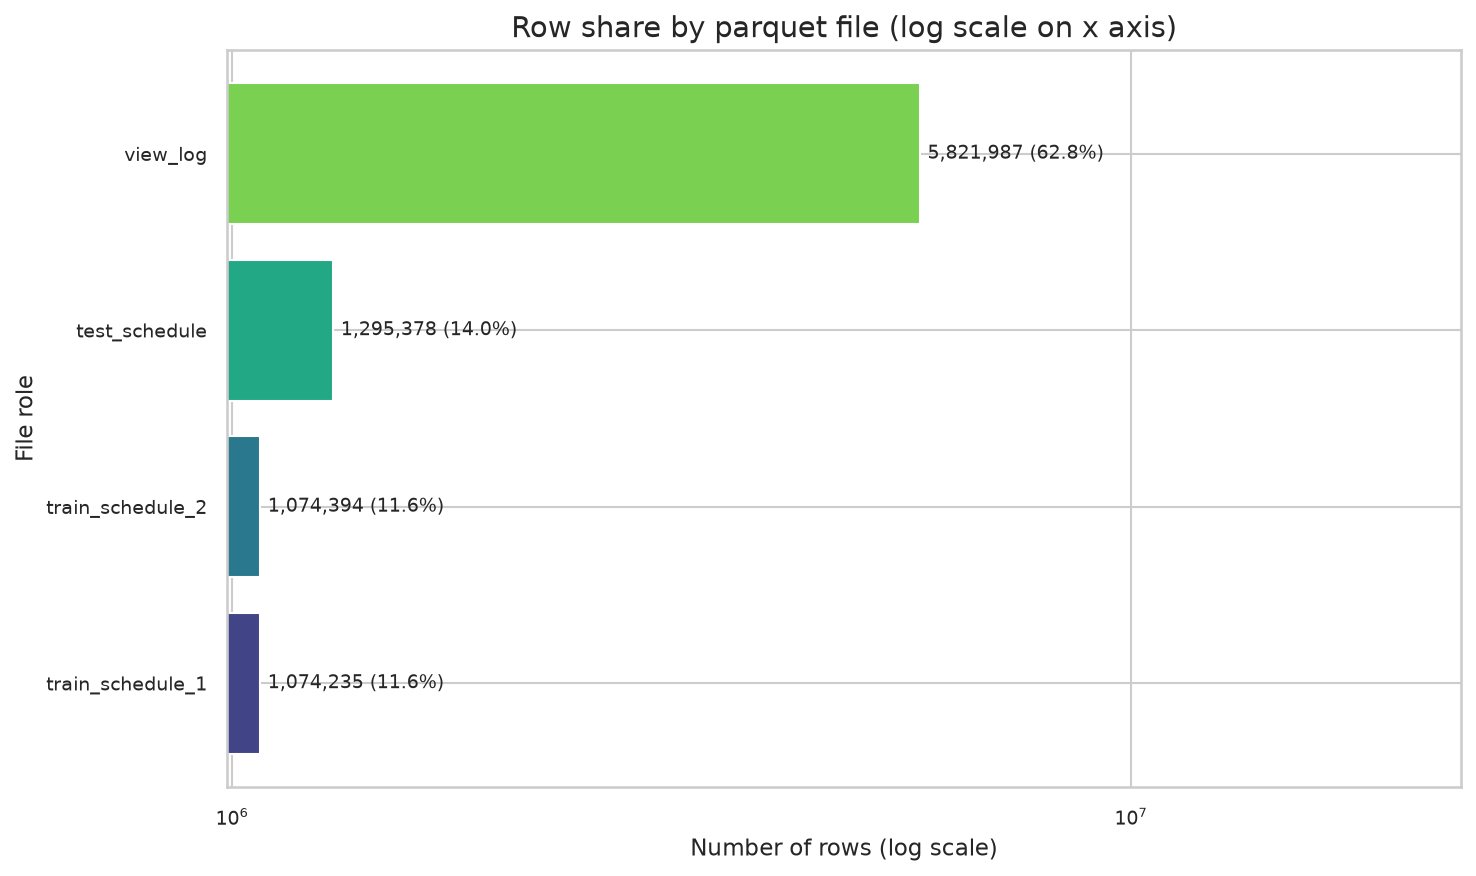

Saved 01_file_overview.png | total parquet rows: 9265994


In [9]:
row_share = file_overview.set_index("role")["n_rows"].sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("viridis", len(row_share))
bars = ax.barh(row_share.index, row_share.values, color=colors)
ax.set_xscale("log")
ax.set_title("Row share by parquet file (log scale on x axis)")
ax.set_xlabel("Number of rows (log scale)")
ax.set_ylabel("File role")
total_rows = row_share.sum()
for bar, value in zip(bars, row_share.values):
    ax.text(value * 1.02, bar.get_y() + bar.get_height() / 2,
            f"{value:,} ({value / total_rows:.1%})", va="center", fontsize=9)
ax.set_xlim(right=row_share.max() * 4)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_file_overview.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 01_file_overview.png | total parquet rows:", int(total_rows))

### Conclusion
The dataset consists of 4 parquet files with a total volume of ~9.27 million rows: one view log (~5.8 million rows, 80 MB, only 5 columns) and three schedule files (train 11–20, train 21–30, test 31–42, each ~1.07–1.30 million rows, 13 columns). The view log runs from 09.03.2020 to 26.07.2020 (ISO weeks 11–30), the schedule runs from 08.03.2020 to 19.10.2020. Missing values (NaN) are present only in the schedule files and are concentrated in the text/numeric descriptive columns (tv_show_genre_*, year_of_production, director, actors), not in the key ones (channel_id, start_time, duration, tv_show_id). The schedule files are linked by dates without gaps: week 21 is the boundary between train1/train2, week 31 is the boundary between train2/test.

## B. View log profile

ISO calendar weeks are used for all week-based views. They give stable Monday-based weekly boundaries, which align better with the weekly schedule exports than calendar month boundaries.

In [10]:
views["iso_week"] = views["start_time"].dt.isocalendar().week.astype("int16")
week_counts = views["iso_week"].value_counts().sort_index()
unique_users = views["user_id"].nunique()
unique_channels = views["vsetv_id"].nunique()
print("Unique user_id:", int(unique_users))
print("Unique vsetv_id:", int(unique_channels))
print("start_time min:", views["start_time"].min())
print("start_time max:", views["start_time"].max())
print("ISO week min/max:", int(week_counts.index.min()), int(week_counts.index.max()))
print("Number of ISO weeks:", int(week_counts.shape[0]))
display(week_counts.rename("n_rows").to_frame())

Unique user_id: 4914
Unique vsetv_id: 202
start_time min: 2020-03-09 00:00:02
start_time max: 2020-07-26 23:58:42
ISO week min/max: 11 30
Number of ISO weeks: 20


,n_rows
iso_week,
11,407493
12,452314
13,465318
14,428820
15,412698
16,406317
17,417854
18,385637
19,336042


In [11]:
duration_summary = views["duration"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
).to_frame("duration_seconds")
display(duration_summary)
n_le_zero = int((views["duration"] <= 0).sum())
n_gt_four_hours = int((views["duration"] > 4 * 3600).sum())
print("Rows with duration <= 0:", n_le_zero, f"({n_le_zero / len(views):.6%})")
print("Rows with duration > 4 hours:", n_gt_four_hours, f"({n_gt_four_hours / len(views):.6%})")

,duration_seconds
count,5.821987e+06
mean,1.480459e+03
std,3.123737e+03
min,6.100000e+01
50%,3.960000e+02
90%,3.911000e+03
95%,6.344000e+03
99%,1.407914e+04
99.9%,3.397600e+04
max,3.421450e+05


Rows with duration <= 0: 0 (0.000000%)
Rows with duration > 4 hours: 55761 (0.957766%)


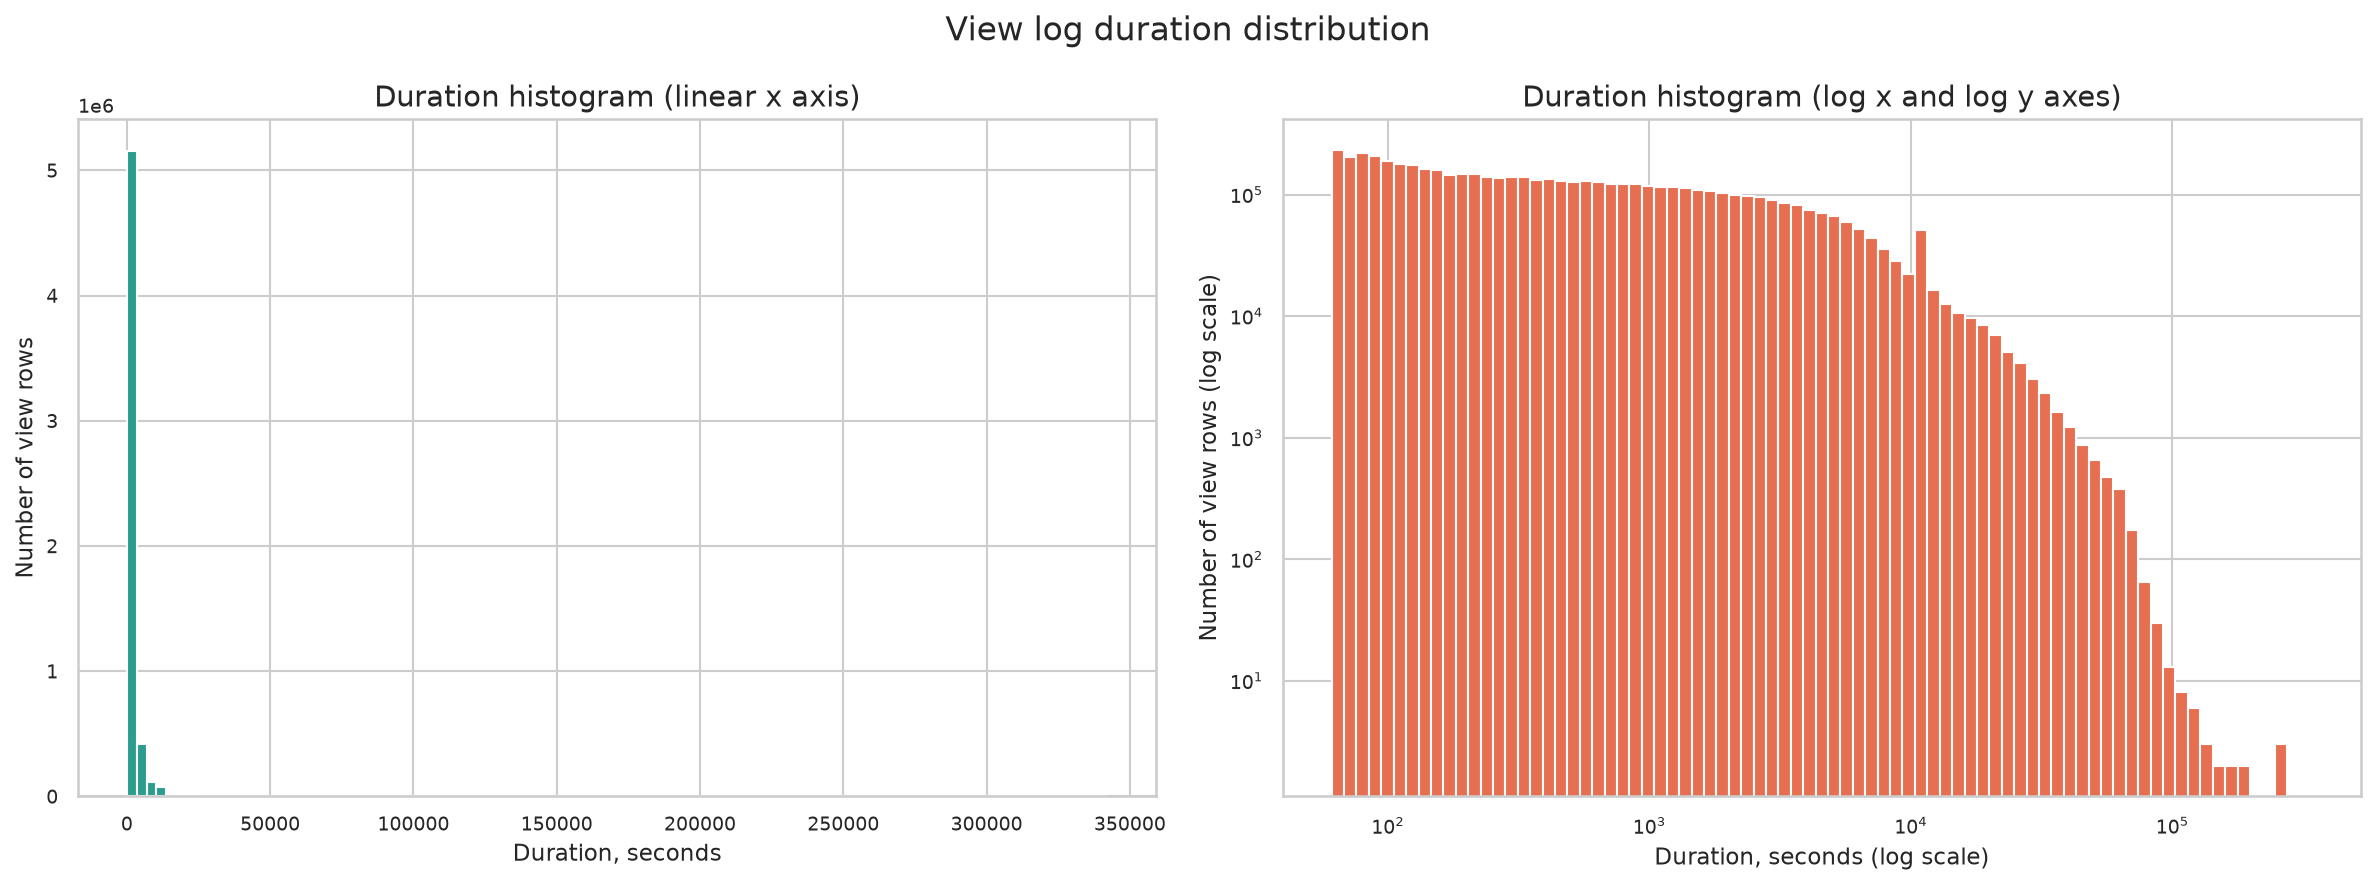

Saved 02_duration_distribution.png


In [12]:
duration_values = views["duration"].to_numpy()
positive = duration_values[duration_values > 0]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].hist(positive, bins=100, color="#2a9d8f")
axes[0].set_title("Duration histogram (linear x axis)")
axes[0].set_xlabel("Duration, seconds")
axes[0].set_ylabel("Number of view rows")

log_bins = np.logspace(np.log10(max(1, positive.min())), np.log10(positive.max()), 80)
axes[1].hist(positive, bins=log_bins, color="#e76f51")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Duration histogram (log x and log y axes)")
axes[1].set_xlabel("Duration, seconds (log scale)")
axes[1].set_ylabel("Number of view rows (log scale)")

fig.suptitle("View log duration distribution", fontsize=16)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_duration_distribution.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 02_duration_distribution.png")

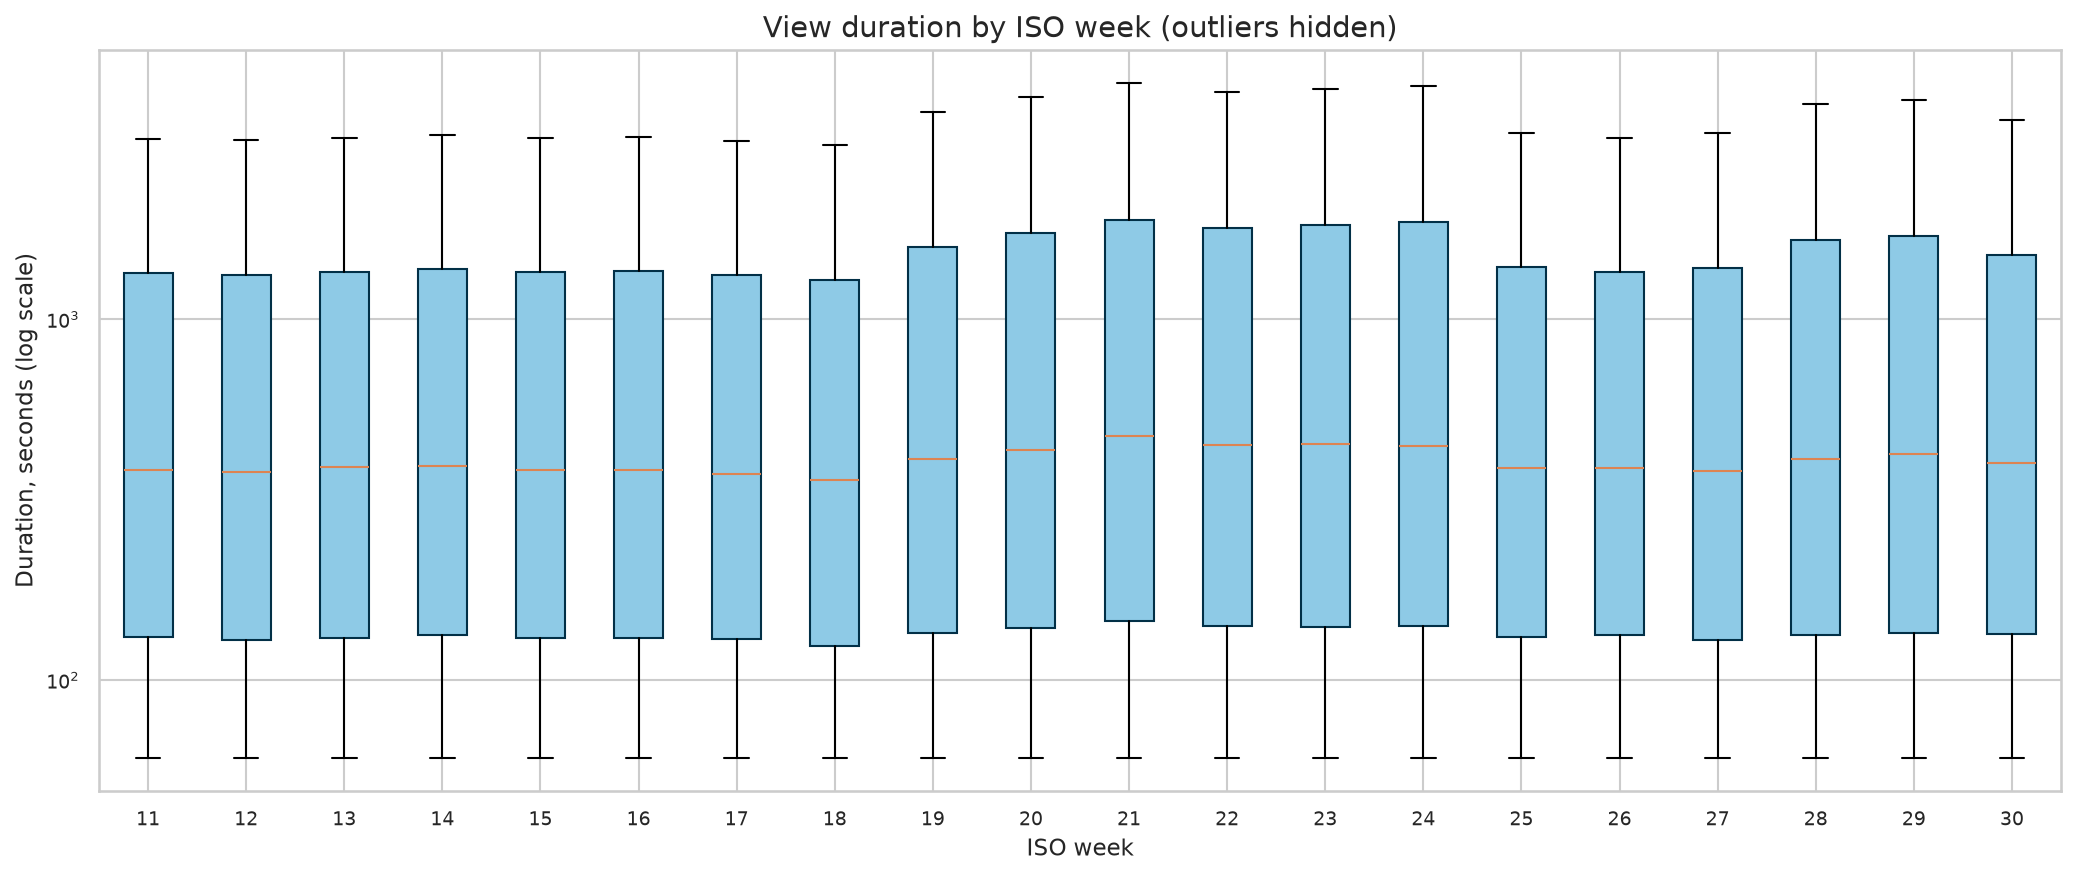

Saved 02_duration_boxplot_by_week.png | groups: 20


In [13]:
week_labels = week_counts.index.to_list()
week_values = [views.loc[views["iso_week"] == week, "duration"].to_numpy() for week in week_labels]
fig, ax = plt.subplots(figsize=(14, 6))
ax.boxplot(week_values, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#8ecae6", "edgecolor": "#023047"})
ax.set_yscale("log")
ax.set_xticks(range(1, len(week_labels) + 1), labels=[str(week) for week in week_labels])
ax.set_title("View duration by ISO week (outliers hidden)")
ax.set_xlabel("ISO week")
ax.set_ylabel("Duration, seconds (log scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_duration_boxplot_by_week.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 02_duration_boxplot_by_week.png | groups:", len(week_values))

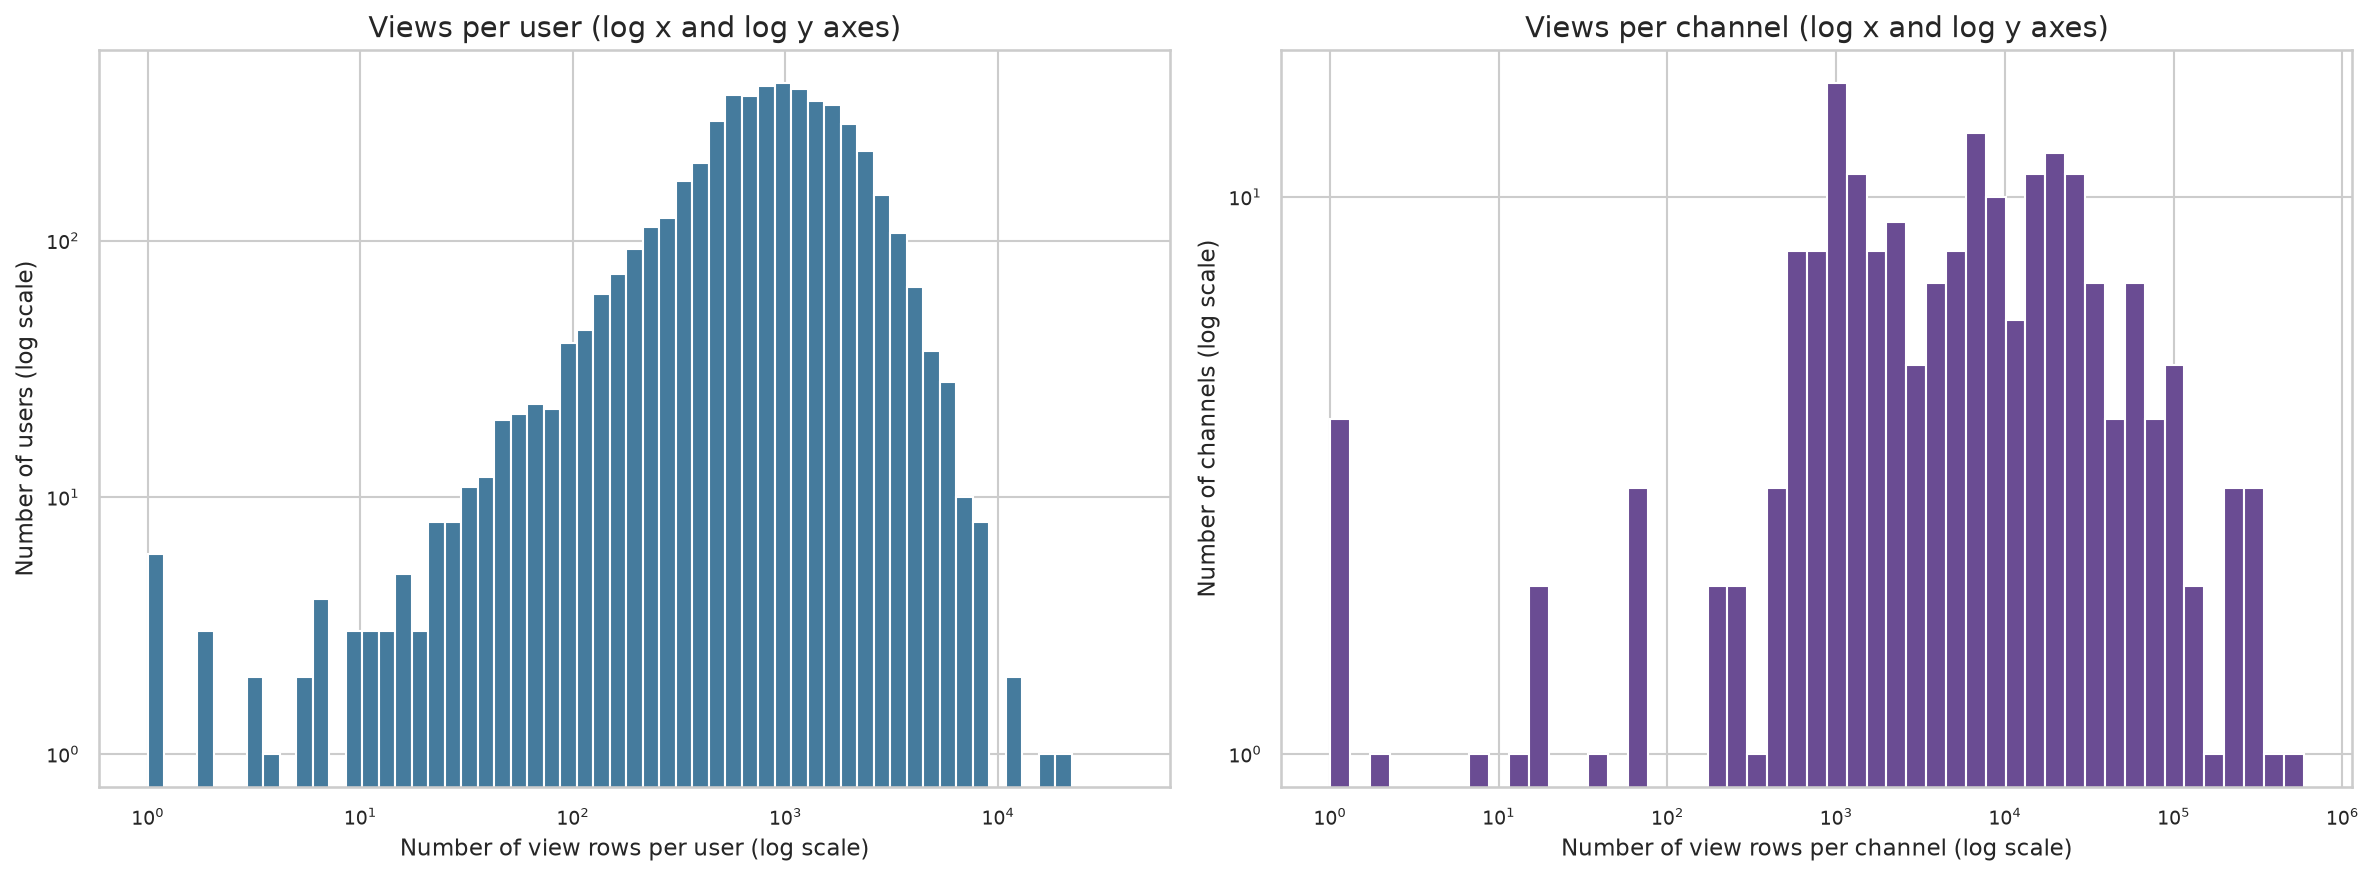

Saved 02_views_per_user_channel.png | users: 4914 | channels: 202 | median views per user: 874.0 | median views per channel: 5901.0


In [14]:
views_per_user = views["user_id"].value_counts()
views_per_channel = views["vsetv_id"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
user_bins = np.logspace(0, np.log10(max(2, views_per_user.max())), 60)
axes[0].hist(views_per_user.to_numpy(), bins=user_bins, color="#457b9d")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Views per user (log x and log y axes)")
axes[0].set_xlabel("Number of view rows per user (log scale)")
axes[0].set_ylabel("Number of users (log scale)")
channel_bins = np.logspace(0, np.log10(max(2, views_per_channel.max())), 50)
axes[1].hist(views_per_channel.to_numpy(), bins=channel_bins, color="#6a4c93")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Views per channel (log x and log y axes)")
axes[1].set_xlabel("Number of view rows per channel (log scale)")
axes[1].set_ylabel("Number of channels (log scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_views_per_user_channel.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 02_views_per_user_channel.png | users:", int(views_per_user.shape[0]),
      "| channels:", int(views_per_channel.shape[0]),
      "| median views per user:", float(views_per_user.median()),
      "| median views per channel:", float(views_per_channel.median()))

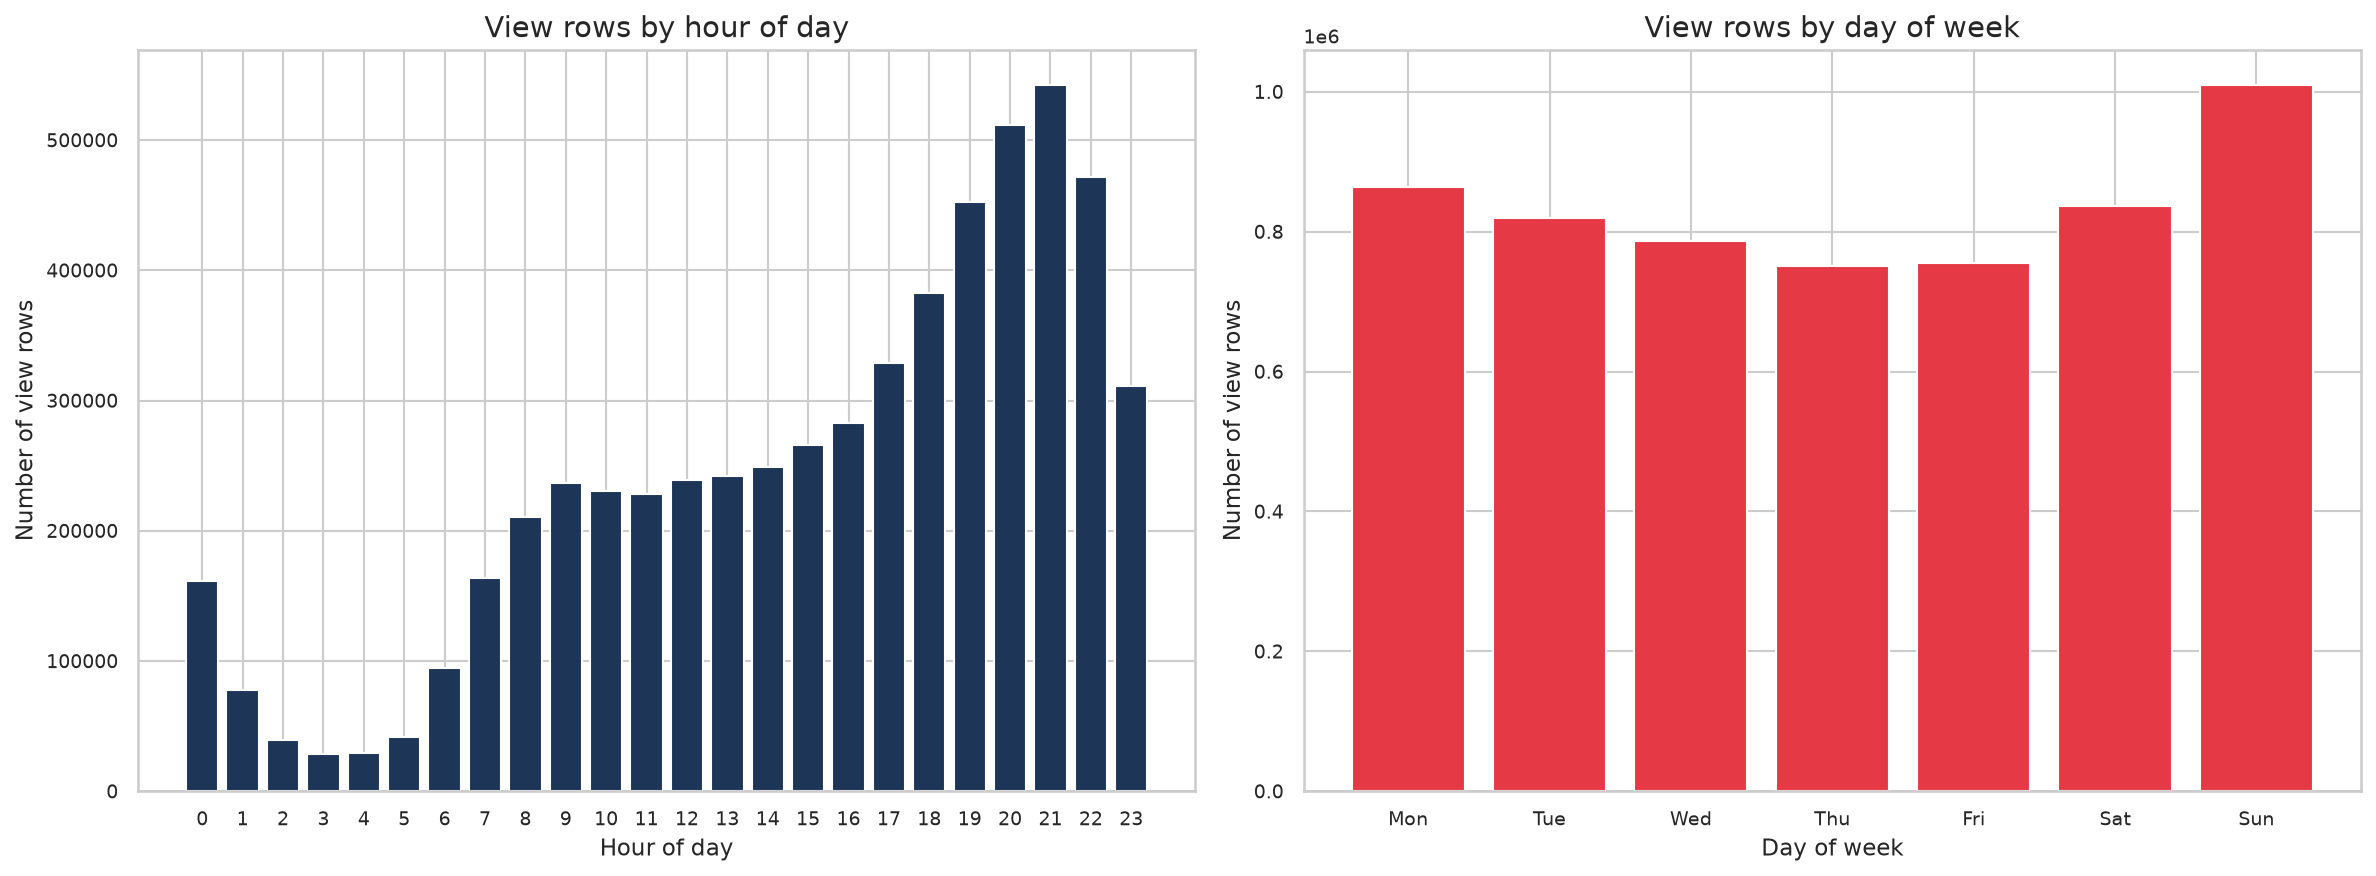

Saved 02_hour_weekday_activity.png | peak hour: 21 | peak weekday: Sun


In [15]:
hour_counts = np.bincount(views["start_time"].dt.hour.to_numpy(), minlength=24)
weekday_counts = np.bincount(views["start_time"].dt.dayofweek.to_numpy(), minlength=7)
weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(np.arange(24), hour_counts, color="#1d3557")
axes[0].set_title("View rows by hour of day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Number of view rows")
axes[0].set_xticks(np.arange(24))
axes[1].bar(weekday_labels, weekday_counts, color="#e63946")
axes[1].set_title("View rows by day of week")
axes[1].set_xlabel("Day of week")
axes[1].set_ylabel("Number of view rows")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_hour_weekday_activity.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 02_hour_weekday_activity.png | peak hour:", int(hour_counts.argmax()),
      "| peak weekday:", weekday_labels[int(weekday_counts.argmax())])

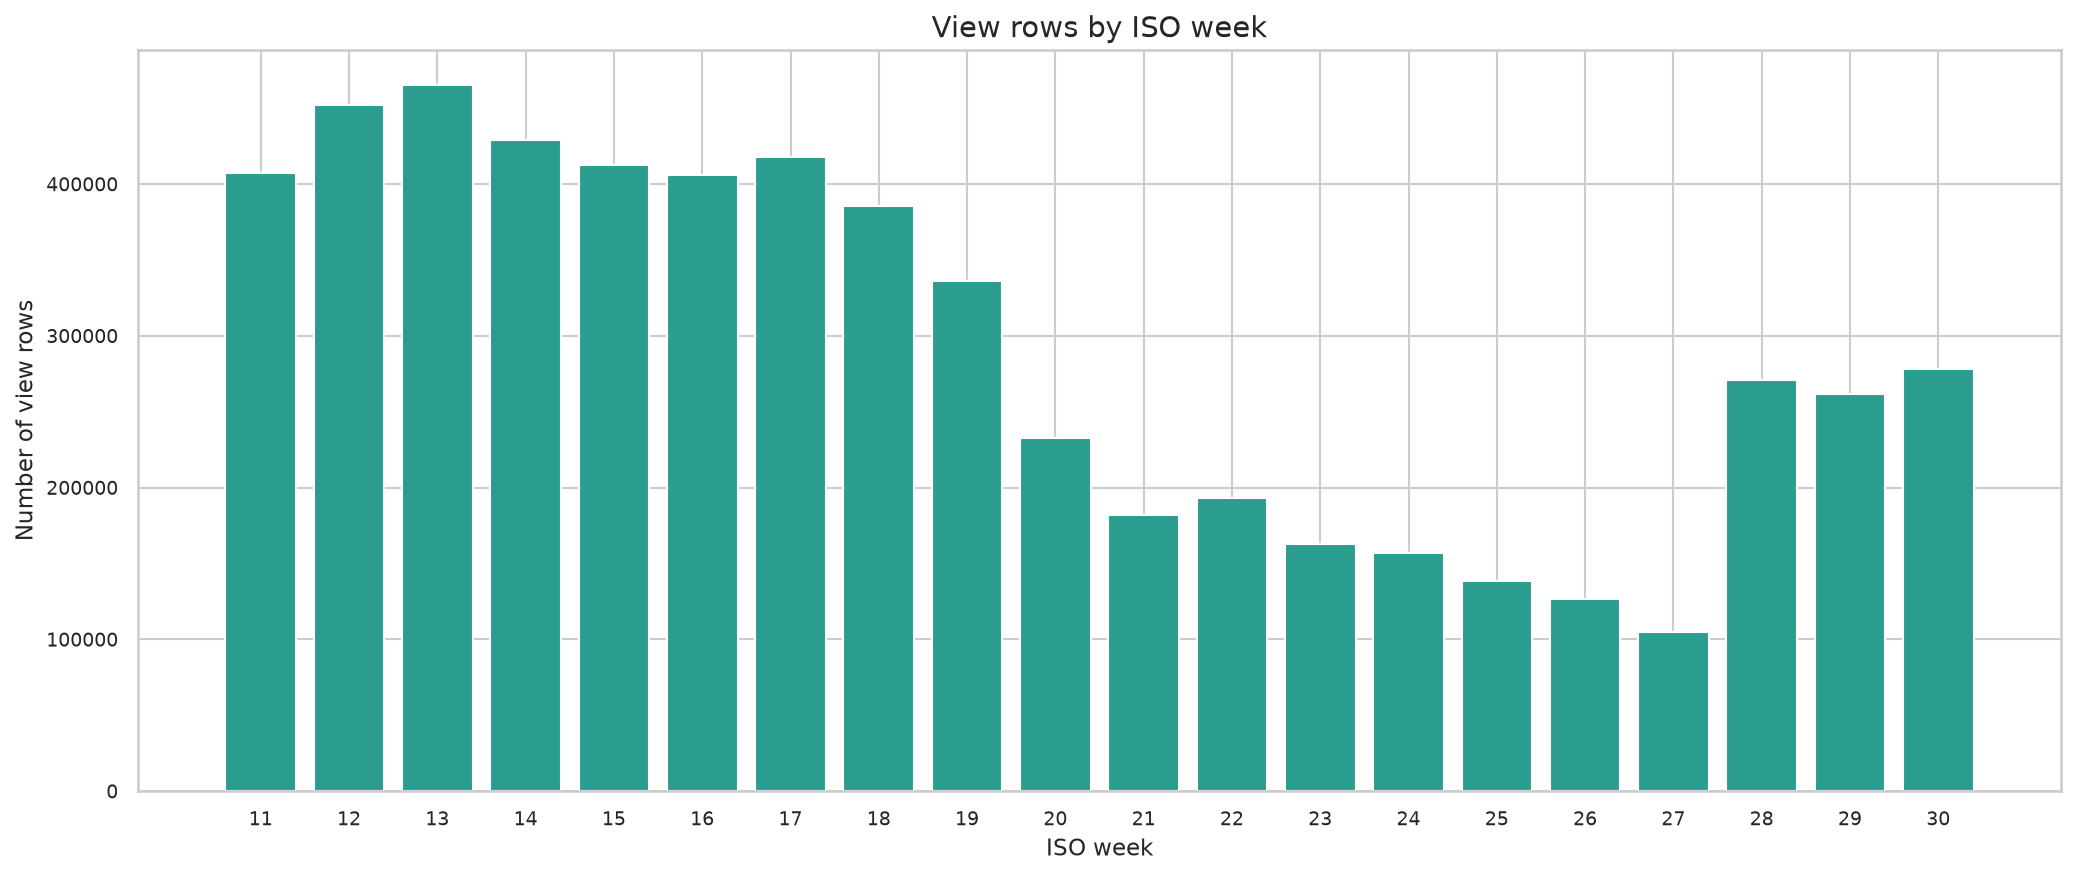

Saved 02_rows_by_week.png
start_time range: 2020-03-09 00:00:02 to 2020-07-26 23:58:42


In [16]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(week_counts.index.astype(str), week_counts.values, color="#2a9d8f")
ax.set_title("View rows by ISO week")
ax.set_xlabel("ISO week")
ax.set_ylabel("Number of view rows")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_rows_by_week.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 02_rows_by_week.png")
print("start_time range:", views["start_time"].min(), "to", views["start_time"].max())

### Conclusion
The log contains 4,914 unique users and 202 unique channels over 20 ISO weeks. The duration distribution is heavily skewed to the right: median 396 s (~6.6 min), mean 1,480 s, 99th percentile 14,079 s (~3.9 h), and maximum 342,145 s (~95 h). There are no rows with duration <= 0, but 55,761 rows (0.96%) are longer than 4 hours. Peak activity is at 21:00, and by day of week it is Sunday. Weekly volume is 385,637-465,318 rows in weeks 11-18, falls to 105,223-336,042 rows in weeks 19-27, and rebounds to 261,698-278,122 rows in weeks 28-30. The distribution of views per user and per channel has a long tail (median 874 view rows per user and 5,901 per channel), which is expected for the TV domain.

## C. Schedule profile

In [17]:
def concat_schedule_core(schedule_dict):
    columns = [
        "channel_id", "start_time", "duration", "tv_show_id",
        "tv_show_category", "tv_show_genre_1",
    ]
    frames = []
    for role in SCHEDULE_PATHS:
        part = schedule_dict[role][columns].copy()
        part["role"] = role
        frames.append(part)
    for column in ["tv_show_category", "tv_show_genre_1"]:
        union_categories = pd.api.types.union_categoricals(
            [part[column] for part in frames]
        ).categories
        for part in frames:
            part[column] = part[column].cat.set_categories(union_categories)
    return pd.concat(frames, ignore_index=True)


combined_schedule_core = concat_schedule_core(schedules)
rows_before_dedup = int(combined_schedule_core.shape[0])
combined_schedule_core = combined_schedule_core.drop_duplicates(
    subset=["channel_id", "start_time"], keep="first"
).reset_index(drop=True)
rows_after_dedup = int(combined_schedule_core.shape[0])
duplicates_removed = rows_before_dedup - rows_after_dedup
combined_schedule_core["role"] = combined_schedule_core["role"].astype("category")

print("Combined schedule rows before deduplication:", rows_before_dedup)
print("Combined schedule rows after deduplication:", rows_after_dedup)
print("Duplicate rows removed by (channel_id, start_time):", duplicates_removed)
print("Rows by role after deduplication:")
display(combined_schedule_core["role"].value_counts().rename("n_rows").to_frame())
display(combined_schedule_core.head(5), title="Deduplicated combined schedule head (non-ASCII)")

Combined schedule rows before deduplication: 3444007
Combined schedule rows after deduplication: 3444006
Duplicate rows removed by (channel_id, start_time): 1
Rows by role after deduplication:


,n_rows
role,
test_schedule,1295378
train_schedule_2,1074394
train_schedule_1,1074234


,channel_id,start_time,duration,tv_show_id,tv_show_category,tv_show_genre_1,role
0,3,2020-03-09 06:00:00,6000,0,Другое,NaN,train_schedule_1
1,3,2020-03-09 07:40:00,5400,2400480,Инфо,общество и политика,train_schedule_1
2,3,2020-03-09 09:10:00,8400,700475,Развлечения,музыка,train_schedule_1
3,3,2020-03-09 11:30:00,28800,0,Сериалы,NaN,train_schedule_1
4,3,2020-03-09 19:30:00,2700,2400480,Инфо,общество и политика,train_schedule_1


In [18]:
schedule_summary_rows = []
for role, path in SCHEDULE_PATHS.items():
    frame = schedules[role]
    nonzero = frame[frame["tv_show_id"] != 0]
    weeks = frame["start_time"].dt.isocalendar().week.astype("int16")
    schedule_summary_rows.append({
        "role": role,
        "file": path.name,
        "n_rows": int(frame.shape[0]),
        "unique_channel_id": int(frame["channel_id"].nunique()),
        "unique_tv_show_id_nonzero": int(nonzero["tv_show_id"].nunique()),
        "share_tv_show_id_nonzero": nonzero.shape[0] / frame.shape[0],
        "n_tv_show_id_zero": int((frame["tv_show_id"] == 0).sum()),
        "start_time_min": frame["start_time"].min(),
        "start_time_max": frame["start_time"].max(),
        "n_iso_weeks": int(weeks.nunique()),
        "iso_week_min": int(weeks.min()),
        "iso_week_max": int(weeks.max()),
    })

schedule_summary = pd.DataFrame(schedule_summary_rows)
display(schedule_summary)
for row in schedule_summary_rows:
    print(f"{row['role']}: share of rows with tv_show_id != 0 = {row['share_tv_show_id_nonzero']:.8f}")

,role,file,n_rows,unique_channel_id,unique_tv_show_id_nonzero,share_tv_show_id_nonzero,n_tv_show_id_zero,start_time_min,start_time_max,n_iso_weeks,iso_week_min,iso_week_max
0,train_schedule_1,export_arh_11-20-final.parquet,1074235,400,5847,0.107624,958622,2020-03-08 23:00:00,2020-05-18 11:45:00,12,10,21
1,train_schedule_2,export_arh_21-30-final.parquet,1074394,403,6363,0.113092,952889,2020-05-18 00:00:00,2020-07-27 11:55:00,11,21,31
2,test_schedule,export_arh_31-42-final.parquet,1295378,404,6636,0.111762,1150604,2020-07-27 00:00:00,2020-10-19 11:55:00,13,31,43


train_schedule_1: share of rows with tv_show_id != 0 = 0.10762356
train_schedule_2: share of rows with tv_show_id != 0 = 0.11309166
test_schedule: share of rows with tv_show_id != 0 = 0.11176197


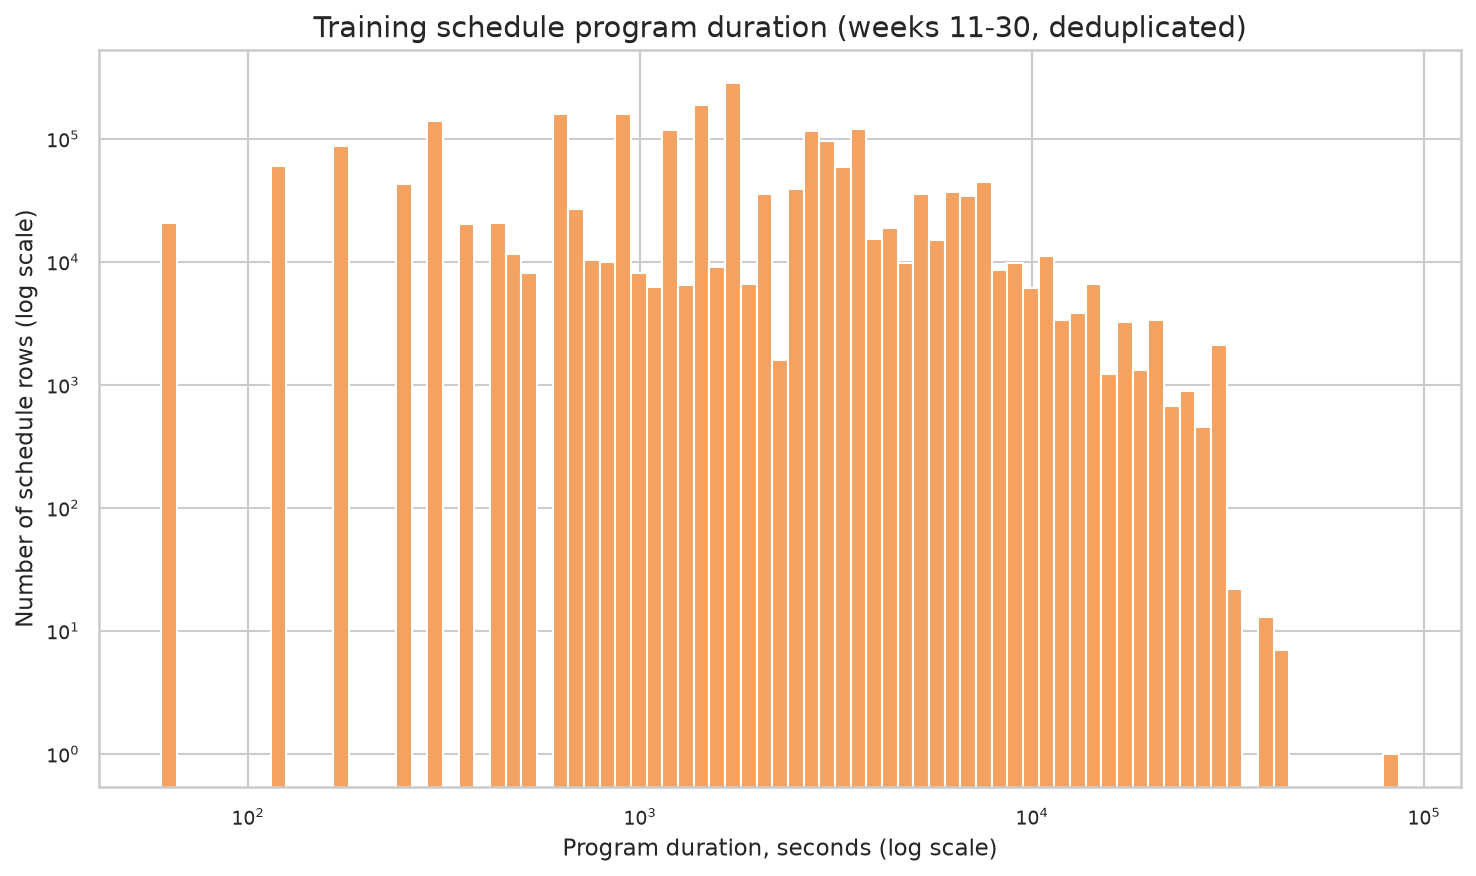

Saved 03_schedule_duration_distribution.png | zero-duration rows: 1 | rows: 2148628


In [19]:
train_schedule_mask = combined_schedule_core["role"].isin(TRAIN_SCHEDULE_ROLES)
train_duration = combined_schedule_core.loc[train_schedule_mask, "duration"]
positive_train_duration = train_duration[train_duration > 0]
fig, ax = plt.subplots(figsize=(10, 6))
log_bins = np.logspace(
    np.log10(max(1, positive_train_duration.min())),
    np.log10(positive_train_duration.max()),
    80,
)
ax.hist(positive_train_duration, bins=log_bins, color="#f4a261")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Training schedule program duration (weeks 11-30, deduplicated)")
ax.set_xlabel("Program duration, seconds (log scale)")
ax.set_ylabel("Number of schedule rows (log scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_schedule_duration_distribution.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 03_schedule_duration_distribution.png | zero-duration rows:",
      int((train_duration == 0).sum()), "| rows:", int(train_duration.shape[0]))

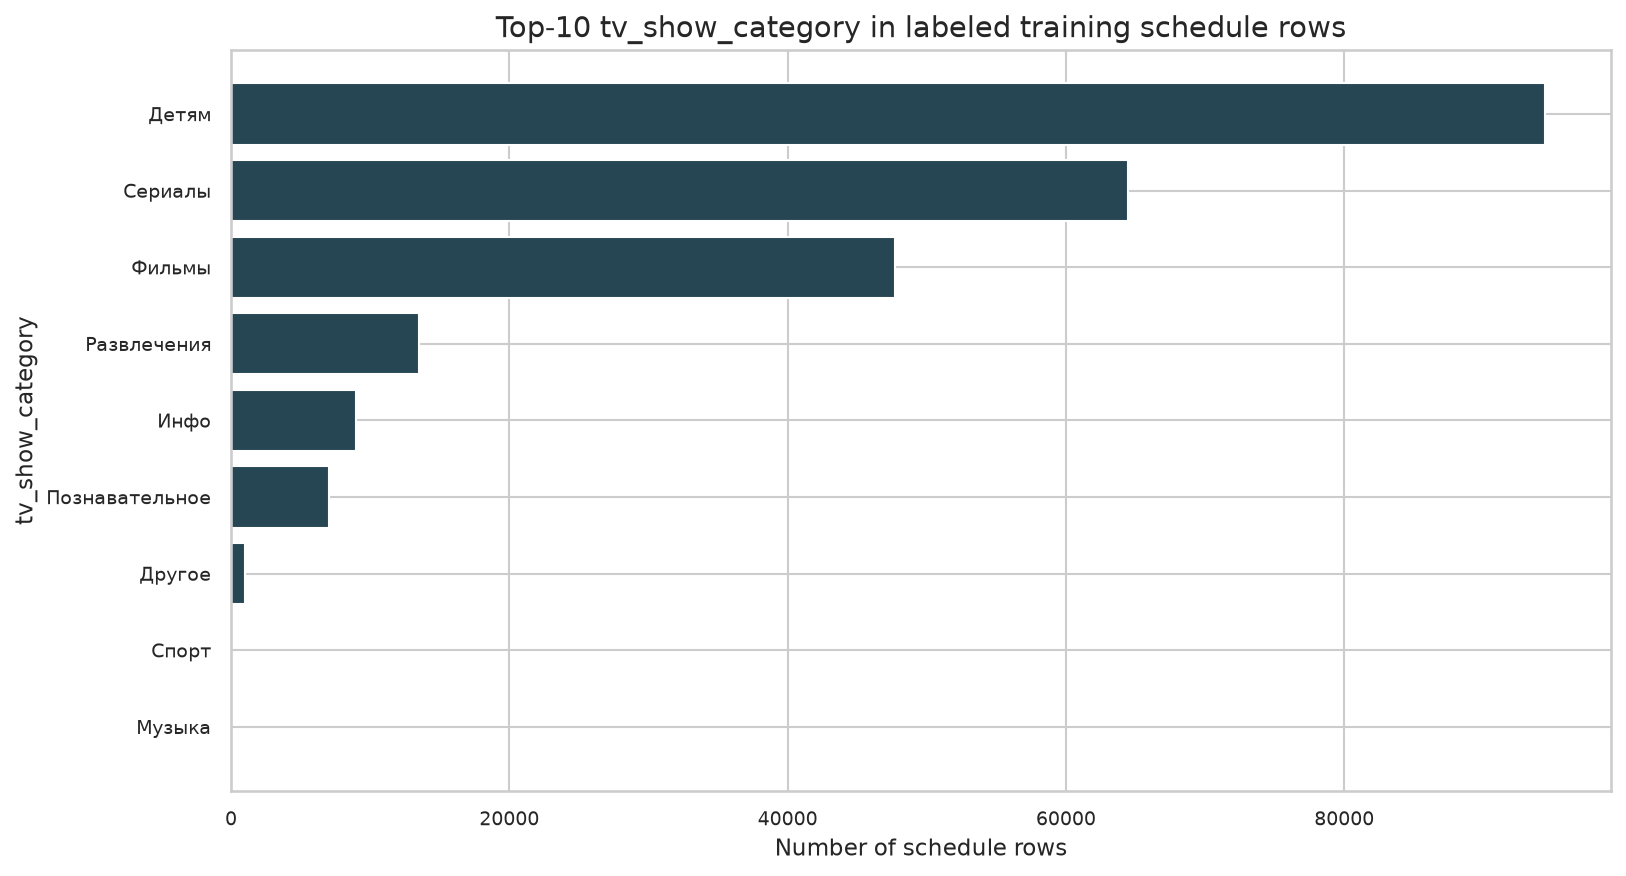

Saved 03_top_categories.png | categories plotted: 9 | labeled rows: 237118


In [20]:
train_labeled_mask = (
    combined_schedule_core["role"].isin(TRAIN_SCHEDULE_ROLES)
    & (combined_schedule_core["tv_show_id"] != 0)
)
train_labeled = combined_schedule_core.loc[train_labeled_mask]
top_categories = train_labeled["tv_show_category"].value_counts().head(10).sort_values()
category_labels = list(top_categories.index)
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(category_labels, top_categories.values, color="#264653")
ax.set_title("Top-10 tv_show_category in labeled training schedule rows")
ax.set_xlabel("Number of schedule rows")
ax.set_ylabel("tv_show_category")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_top_categories.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 03_top_categories.png | categories plotted:", int(top_categories.shape[0]),
      "| labeled rows:", int(train_labeled.shape[0]))

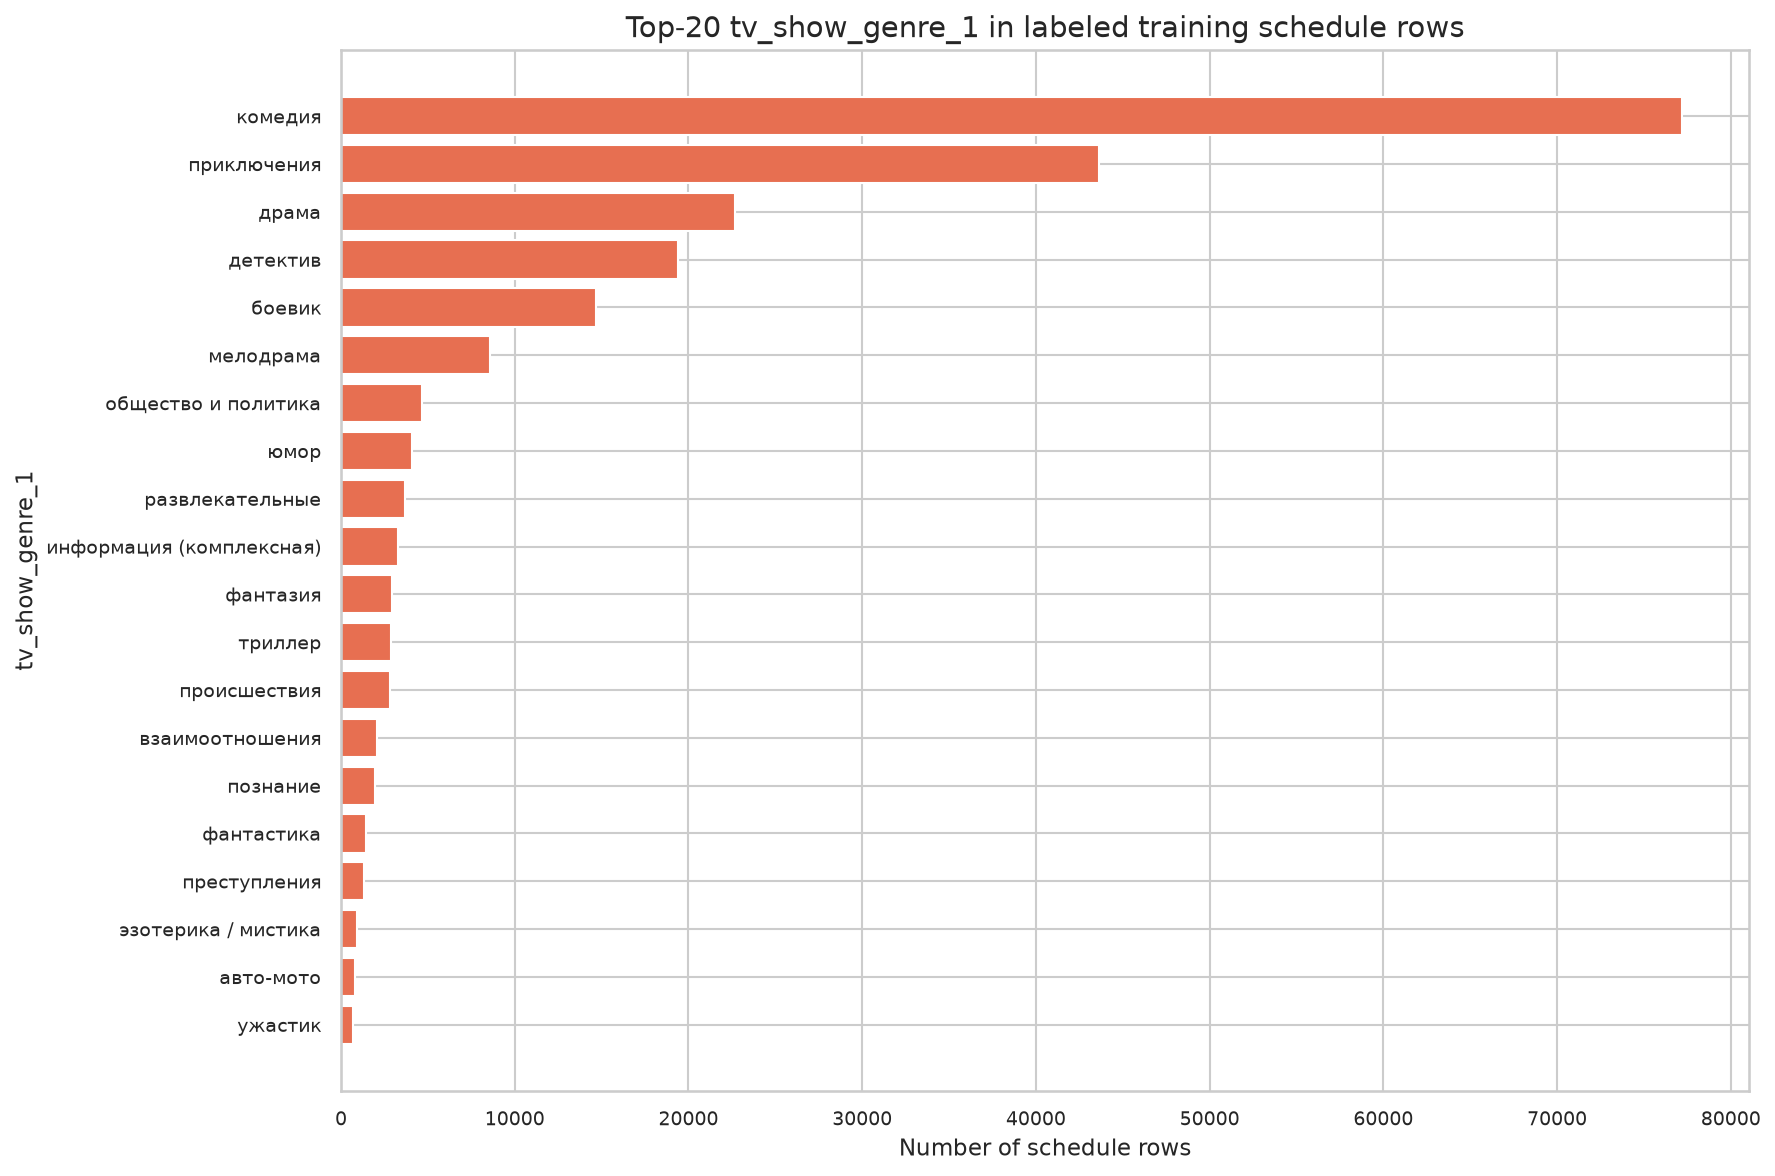

Saved 03_top_genres.png | genres plotted: 20


In [21]:
top_genres = train_labeled["tv_show_genre_1"].value_counts().head(20).sort_values()
genre_labels = list(top_genres.index)
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(genre_labels, top_genres.values, color="#e76f51")
ax.set_title("Top-20 tv_show_genre_1 in labeled training schedule rows")
ax.set_xlabel("Number of schedule rows")
ax.set_ylabel("tv_show_genre_1")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_top_genres.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 03_top_genres.png | genres plotted:", int(top_genres.shape[0]))

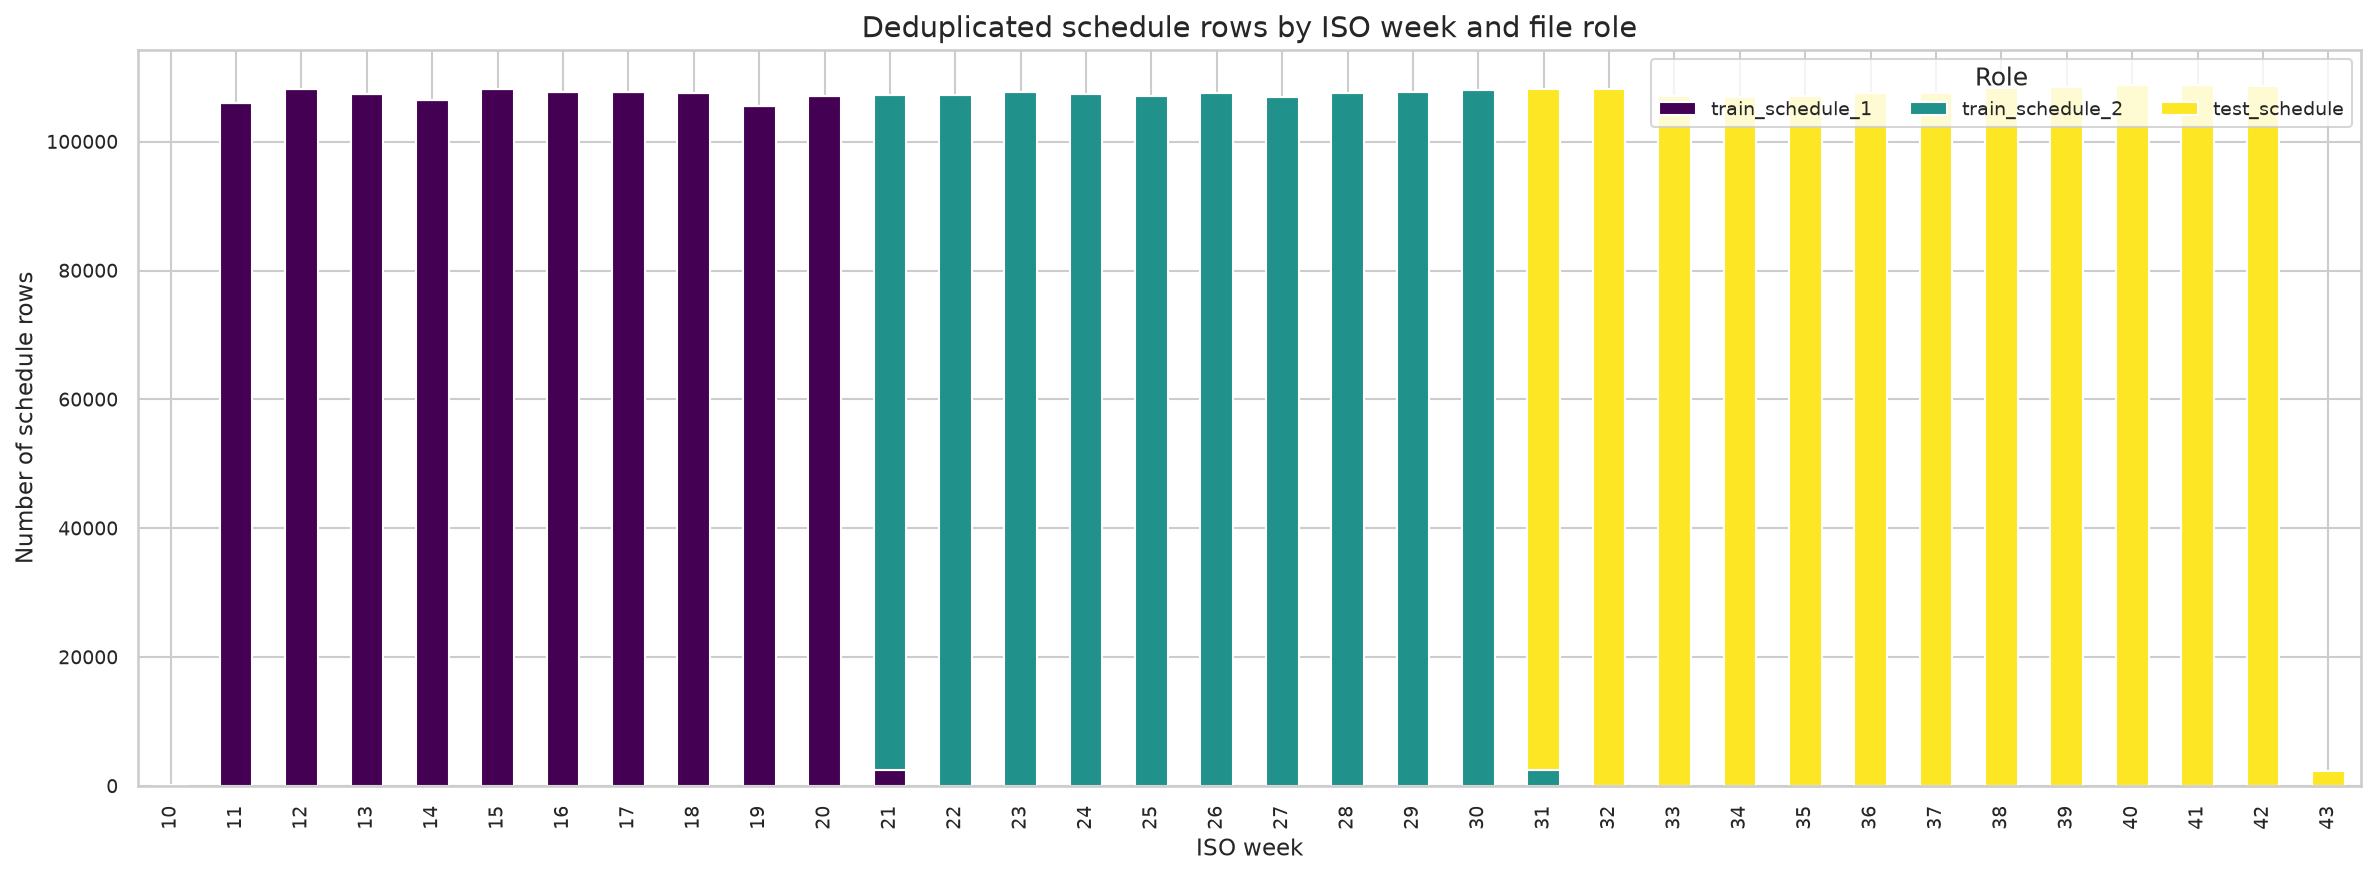

Saved 03_rows_by_week.png | weeks: 34


,train_schedule_1,train_schedule_2,test_schedule
week,,,
10,86,0,0
11,106036,0,0
12,108177,0,0
13,107362,0,0
14,106527,0,0
15,108126,0,0
16,107697,0,0
17,107721,0,0
18,107505,0,0


In [22]:
week_counts_by_role = {}
for role in SCHEDULE_PATHS:
    role_frame = combined_schedule_core[combined_schedule_core["role"] == role]
    weeks = role_frame["start_time"].dt.isocalendar().week.astype("int16")
    week_counts_by_role[role] = weeks.value_counts().sort_index()
week_matrix = pd.DataFrame(week_counts_by_role).fillna(0).sort_index()
fig, ax = plt.subplots(figsize=(16, 6))
week_matrix.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_title("Deduplicated schedule rows by ISO week and file role")
ax.set_xlabel("ISO week")
ax.set_ylabel("Number of schedule rows")
ax.legend(title="Role", ncol=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_rows_by_week.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 03_rows_by_week.png | weeks:", int(week_matrix.shape[0]))
display(week_matrix.astype("int64"))

### Conclusion
After combining the three files and deduplicating by (channel_id, start_time), we obtained 3,444,006 rows (only 1 duplicate was removed). The training core (weeks 11-30) contains 2,148,628 rows and is used for matching with the logs. The files contain 400, 403, and 404 unique channels; the number of unique tv_show_id values other than zero is 5,847, 6,363, and 6,636. Only 10.76%, 11.31%, and 11.18% of schedule rows have a non-zero tv_show_id, so about 89% of schedule rows are programs without an id. Some of these rows are ads or intros, but regular programs also appear among them; the reasons for missing ids are not established. These rows are excluded from matching. There is 1 row with zero duration. The duration distribution has a typical TV shape: advertising and news blocks of 1-10 minutes and series or films up to 1-3 hours. Top categories and genres are predictable (Info, Entertainment, Series; society and politics, music, and similar).

## D. Join quality and interaction definition

A view and a program are joined when channel_id equals vsetv_id and their time intervals overlap. The overlap is computed in integer seconds: overlap_s = max(0, min(view_end, program_end) - max(view_start, program_start)). The threshold 0.8 is a candidate threshold chosen by myself; it is not a rule stated in the competition or exam materials. It is compared with 0.3 and 0.5 in evaluation.ipynb.

In [23]:
print("Imported build_overlap_pairs, build_airing_table, build_aggregated_items, and items_for_weeks from src.data.")

Imported build_overlap_pairs, build_airing_table, build_aggregated_items, and items_for_weeks from src.data.


### B1. Data quality: overlapping views

View rows can be duplicated when one user watches the same channel from several devices. In the observed log one user-show pair for tv_show_id 2400480 had total_watched_s = 2,276,062 s while the summed schedule duration was 569,100 s, exactly four times lower. Such rows inflate watched time and qualified_airings, and the aggregate ratio can hide the problem through min(watched_s, show_duration). The overlap merge below collapses only genuinely intersecting intervals for each (user_id, vsetv_id) pair. Intervals that touch at an endpoint remain separate.

In [24]:
views_merged = merge_overlapping_views(views)
views_merged["iso_week"] = views_merged["start_time"].dt.isocalendar().week.astype("int16")

views_rows_before = int(views.shape[0])
views_rows_after = int(views_merged.shape[0])
views_reduction_pct = 100.0 * (1.0 - views_rows_after / views_rows_before)
print("View rows before merge:", views_rows_before)
print("View rows after merge:", views_rows_after)
print("View rows removed:", views_rows_before - views_rows_after)
print("View row reduction percent:", round(views_reduction_pct, 4))
print("Watched seconds before merge:", int(views["duration"].sum()))
print("Watched seconds after merge:", int(views_merged["duration"].sum()))
display(views_merged.head(5))

View rows before merge: 5821987
View rows after merge: 5725415
View rows removed: 96572
View row reduction percent: 1.6587


Watched seconds before merge: 8619215224
Watched seconds after merge: 8503411121


,user_id,vsetv_id,start_time,stop_time,duration,iso_week
0,2244466330591177,3,2020-03-11 17:07:40,2020-03-11 17:09:52,132,11
1,2244466330591177,3,2020-03-16 11:03:23,2020-03-16 11:04:42,79,12
2,2244466330591177,3,2020-03-16 12:09:49,2020-03-16 12:16:33,404,12
3,2244466330591177,3,2020-03-18 19:24:12,2020-03-18 19:39:50,938,12
4,2244466330591177,3,2020-03-26 19:31:34,2020-03-26 19:59:42,1688,13


In [25]:
join_started = time.time()
train_schedule_mask = combined_schedule_core["role"].isin(TRAIN_SCHEDULE_ROLES)
train_schedule_core = combined_schedule_core.loc[
    train_schedule_mask,
    ["channel_id", "start_time", "duration", "tv_show_id"],
].reset_index(drop=True)
print("Training schedule core shape after boundary deduplication:", train_schedule_core.shape)

overlap_arrays = build_overlap_pairs(views_merged, train_schedule_core)
print("Schedule end-time nondecreasing within each channel:", bool(overlap_arrays["end_monotonic"]))
n_candidates = int(overlap_arrays["n_candidates"])
pair_view_index = overlap_arrays["view_idx"]
pair_program_index = overlap_arrays["sched_idx"]
pair_overlap = overlap_arrays["overlap_s"]

pair = pd.DataFrame({
    "user_id": views_merged["user_id"].to_numpy()[pair_view_index],
    "tv_show_id": train_schedule_core["tv_show_id"].to_numpy()[pair_program_index],
    "overlap_s": pair_overlap,
    "view_idx": pair_view_index,
    "sched_idx": pair_program_index,
    "view_duration": views_merged["duration"].to_numpy()[pair_view_index],
    "show_duration": train_schedule_core["duration"].to_numpy()[pair_program_index],
})

del overlap_arrays, pair_view_index, pair_program_index, pair_overlap
gc.collect()

print("Candidate view-program interval pairs:", n_candidates)
print("Positive-overlap pairs after excluding tv_show_id == 0:", int(pair.shape[0]))
print("Unique users in pairs:", int(pair["user_id"].nunique()))
print("Unique tv_show_id in pairs:", int(pair["tv_show_id"].nunique()))
print("Unique views with at least one pair:", int(pair["view_idx"].nunique()))
print("Overlap seconds min/median/max:", int(pair["overlap_s"].min()),
      float(pair["overlap_s"].median()), int(pair["overlap_s"].max()))
print("Join elapsed seconds:", round(time.time() - join_started, 2))
display(pair.head(10), title="Interaction pair head (non-ASCII)")

Training schedule core shape after boundary deduplication: (2148628, 4)


Schedule end-time nondecreasing within each channel: True


Candidate view-program interval pairs: 7631029
Positive-overlap pairs after excluding tv_show_id == 0: 3763634
Unique users in pairs: 4895
Unique tv_show_id in pairs: 4363


Unique views with at least one pair: 2894949


Overlap seconds min/median/max: 1 524.0 30000
Join elapsed seconds: 26.23


,user_id,tv_show_id,overlap_s,view_idx,sched_idx,view_duration,show_duration
0,8984868078900607602,2400480,455,2785033,1,9346,5400
1,670672473919273448,2400480,1911,167563,1,10226,5400
2,11324904839944973786,2400480,3107,3518534,1,10541,5400
3,11532967343103994950,2400480,2704,3578350,1,9582,5400
4,10522076993540646953,2400480,2908,3276314,1,8636,5400
5,6588209477044984527,2400480,498,1994555,1,5041,5400
6,13866173795451203812,2400480,5400,4301311,1,25916,5400
7,13866173795451203812,700475,8400,4301311,2,25916,8400
8,17891623290872953051,2400480,845,5557321,1,5007,5400
9,4742697566768544548,2400480,241,1383789,1,4002,5400


In [26]:
def apply_threshold(frame, spec):
    if spec["kind"] == "overlap_s":
        mask = frame["overlap_s"] > spec["value"] if spec["strict"] else frame["overlap_s"] >= spec["value"]
    elif spec["kind"] == "view_ratio":
        mask = frame["overlap_s"] / frame["view_duration"].replace(0, np.nan) >= spec["value"]
    elif spec["kind"] == "show_ratio":
        mask = frame["overlap_s"] / frame["show_duration"].replace(0, np.nan) >= spec["value"]
    else:
        raise ValueError(f"Unknown threshold kind: {spec['kind']}")
    return mask.fillna(False)


threshold_rows = []
for threshold_name, spec in INTERACTION_THRESHOLDS.items():
    mask = apply_threshold(pair, spec)
    subset = pair.loc[mask]
    threshold_rows.append({
        "threshold": threshold_name,
        "kind": spec["kind"],
        "value": spec["value"],
        "n_views_with_match": int(subset["view_idx"].nunique()),
        "n_user_show_pairs": int(subset[["user_id", "tv_show_id"]].drop_duplicates().shape[0]),
        "n_pair_rows": int(subset.shape[0]),
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)
print("The 0.8 value is a candidate threshold, not a rule from the competition.")
print("It is included as a candidate overlap threshold, not as an optimized value.")

,threshold,kind,value,n_views_with_match,n_user_show_pairs,n_pair_rows
0,any_overlap_gt_0s,overlap_s,0.0,2894949,1371685,3763634
1,overlap_ge_30s,overlap_s,30.0,2882831,1361281,3711900
2,overlap_ge_60s,overlap_s,60.0,2867737,1350435,3660859
3,overlap_over_view_duration_ge_0.3,view_ratio,0.3,2738901,1184094,2927554
4,overlap_over_view_duration_ge_0.5,view_ratio,0.5,2611475,1090354,2611668
5,overlap_over_show_duration_ge_0.3,show_ratio,0.3,796106,477018,1216141
6,overlap_over_show_duration_ge_0.5,show_ratio,0.5,546398,337070,871547
7,overlap_over_show_duration_ge_0.8_candidate,show_ratio,0.8,330890,208668,565004


The 0.8 value is a candidate threshold, not a rule from the competition.
It is included as a candidate overlap threshold, not as an optimized value.


In [27]:
airing_table = build_airing_table(pair, ratio_threshold=RATIO_THRESHOLD)
print("Airing-level rows:", int(airing_table.shape[0]))
print("Qualified airings:", int(airing_table["qualified"].sum()))

user_show = airing_table.groupby(
    ["user_id", "tv_show_id"], sort=False
).agg(
    total_watched_s=("watched_s", "sum"),
    total_show_duration_s=("show_duration", "sum"),
    qualified_airings=("qualified", "sum"),
).reset_index()
user_show["aggregate_ratio"] = (
    np.minimum(user_show["total_watched_s"], user_show["total_show_duration_s"])
    / user_show["total_show_duration_s"].replace(0, np.nan)
)
user_show["aggregated_qualified"] = user_show["aggregate_ratio"] >= RATIO_THRESHOLD

train_items = user_show[
    user_show["aggregated_qualified"] & (user_show["qualified_airings"] >= 1)
].copy()
items_per_user = train_items.groupby("user_id").size()

aggregated_summary = pd.DataFrame([
    {"metric": "airing_rows", "value": int(airing_table.shape[0])},
    {"metric": "qualified_airing_rows", "value": int(airing_table["qualified"].sum())},
    {"metric": "user_show_rows_aggregate_qualified", "value": int(user_show["aggregated_qualified"].sum())},
    {"metric": "user_show_items_with_qualified_airing", "value": int(train_items.shape[0])},
    {"metric": "users_with_items", "value": int(items_per_user.shape[0])},
    {"metric": "items_per_user_min", "value": float(items_per_user.min())},
    {"metric": "items_per_user_median", "value": float(items_per_user.median())},
    {"metric": "items_per_user_mean", "value": float(items_per_user.mean())},
    {"metric": "items_per_user_max", "value": float(items_per_user.max())},
    {"metric": "users_with_ge_5_items", "value": int((items_per_user >= 5).sum())},
    {"metric": "users_with_lt_5_items", "value": int((items_per_user < 5).sum())},
])
display(aggregated_summary)
display(items_per_user.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("items_per_user"))
display(train_items.head(10), title="Aggregated-rule item candidates head (non-ASCII)")
print("This is a candidate-item count check only, not a submission and not a model.")

Airing-level rows: 3014129
Qualified airings: 611760


,metric,value
0,airing_rows,3.014129e+06
1,qualified_airing_rows,6.117600e+05
2,user_show_rows_aggregate_qualified,1.281510e+05
3,user_show_items_with_qualified_airing,1.281510e+05
4,users_with_items,4.768000e+03
5,items_per_user_min,1.000000e+00
6,items_per_user_median,1.400000e+01
7,items_per_user_mean,2.687731e+01
8,items_per_user_max,2.530000e+02
9,users_with_ge_5_items,4.094000e+03


,items_per_user
count,4768.000000
mean,26.877307
std,33.074470
min,1.000000
50%,14.000000
90%,72.000000
95%,102.000000
99%,153.330000
max,253.000000


,user_id,tv_show_id,total_watched_s,total_show_duration_s,qualified_airings,aggregate_ratio,aggregated_qualified
38,1903062287599050621,2400480,274463,330000,125,0.831706,True
248,3121728570765007822,700475,7669,8400,1,0.912976,True
274,6040358463772390807,700475,11621,12600,2,0.922302,True
374,16927576963848448754,700475,8400,8400,1,1.000000,True
398,4425587139972026917,2400480,106349,132300,37,0.803847,True
434,16926244018236572386,700475,6921,8400,1,0.823929,True
464,12276799313053434804,700475,11709,12900,1,0.907674,True
829,13866173795451203812,90082508,25956,28200,2,0.920426,True
835,9805353293902720461,2400480,102052,114600,33,0.890506,True
881,10118430197643011352,90082508,11707,14100,1,0.830284,True


This is a candidate-item count check only, not a submission and not a model.


In [28]:
control_user_id = np.uint64(13866173795451203812)
control_show_id = 2400480


def control_totals(view_frame, label):
    subset = view_frame.loc[view_frame["user_id"] == control_user_id].copy()
    arrays = build_overlap_pairs(subset, train_schedule_core)
    frame = pd.DataFrame({
        "user_id": subset["user_id"].to_numpy()[arrays["view_idx"]],
        "tv_show_id": train_schedule_core["tv_show_id"].to_numpy()[arrays["sched_idx"]],
        "overlap_s": arrays["overlap_s"],
        "view_idx": arrays["view_idx"],
        "sched_idx": arrays["sched_idx"],
        "view_duration": subset["duration"].to_numpy()[arrays["view_idx"]],
        "show_duration": train_schedule_core["duration"].to_numpy()[arrays["sched_idx"]],
    })
    airing = build_airing_table(frame, ratio_threshold=RATIO_THRESHOLD)
    row = airing.loc[airing["tv_show_id"] == control_show_id]
    watched = int(row["watched_s"].sum())
    show_duration = int(row["show_duration"].sum())
    print(f"{label}: total_watched_s={watched}, total_show_duration_s={show_duration}")
    return watched, show_duration


control_before = control_totals(views, "Before merge")
control_after = control_totals(views_merged, "After merge")
excess_airings = airings_exceeding_duration(airing_table)
print("Airings exceeding duration:", excess_airings)
if excess_airings > 0:
    raise AssertionError(f"Airings with watched_s > show_duration: {excess_airings}")
print("OK: no airing has watched_s > show_duration")


Before merge: total_watched_s=2276062, total_show_duration_s=569100


After merge: total_watched_s=429881, total_show_duration_s=569100
Airings exceeding duration: 0
OK: no airing has watched_s > show_duration


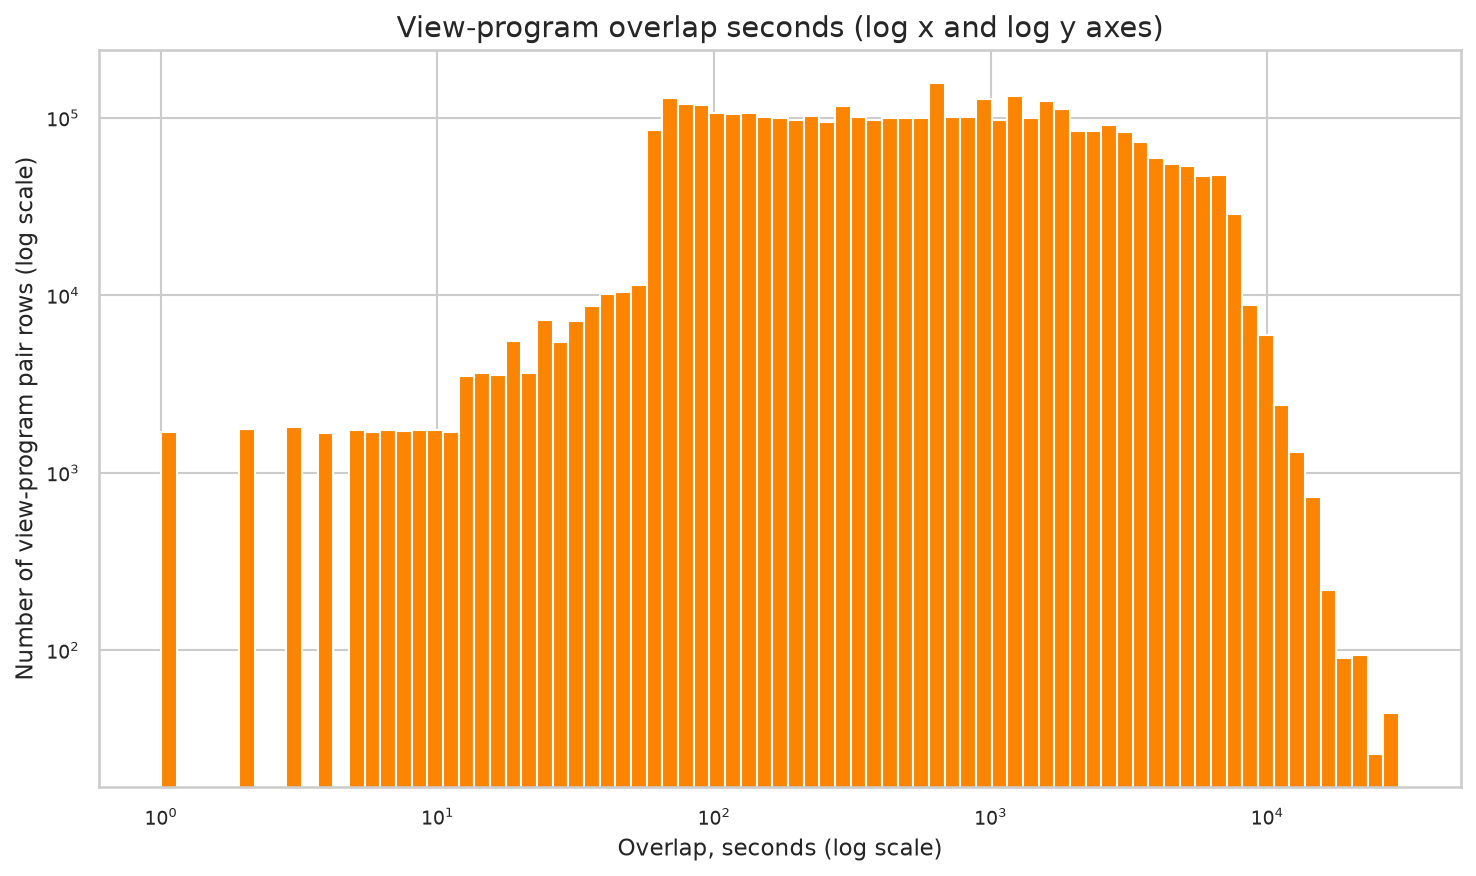

Saved 04_overlap_seconds_distribution.png


In [29]:
overlap_values = pair["overlap_s"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.logspace(0, np.log10(max(1, overlap_values.max())), 80)
ax.hist(overlap_values, bins=bins, color="#fb8500")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("View-program overlap seconds (log x and log y axes)")
ax.set_xlabel("Overlap, seconds (log scale)")
ax.set_ylabel("Number of view-program pair rows (log scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_overlap_seconds_distribution.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 04_overlap_seconds_distribution.png")

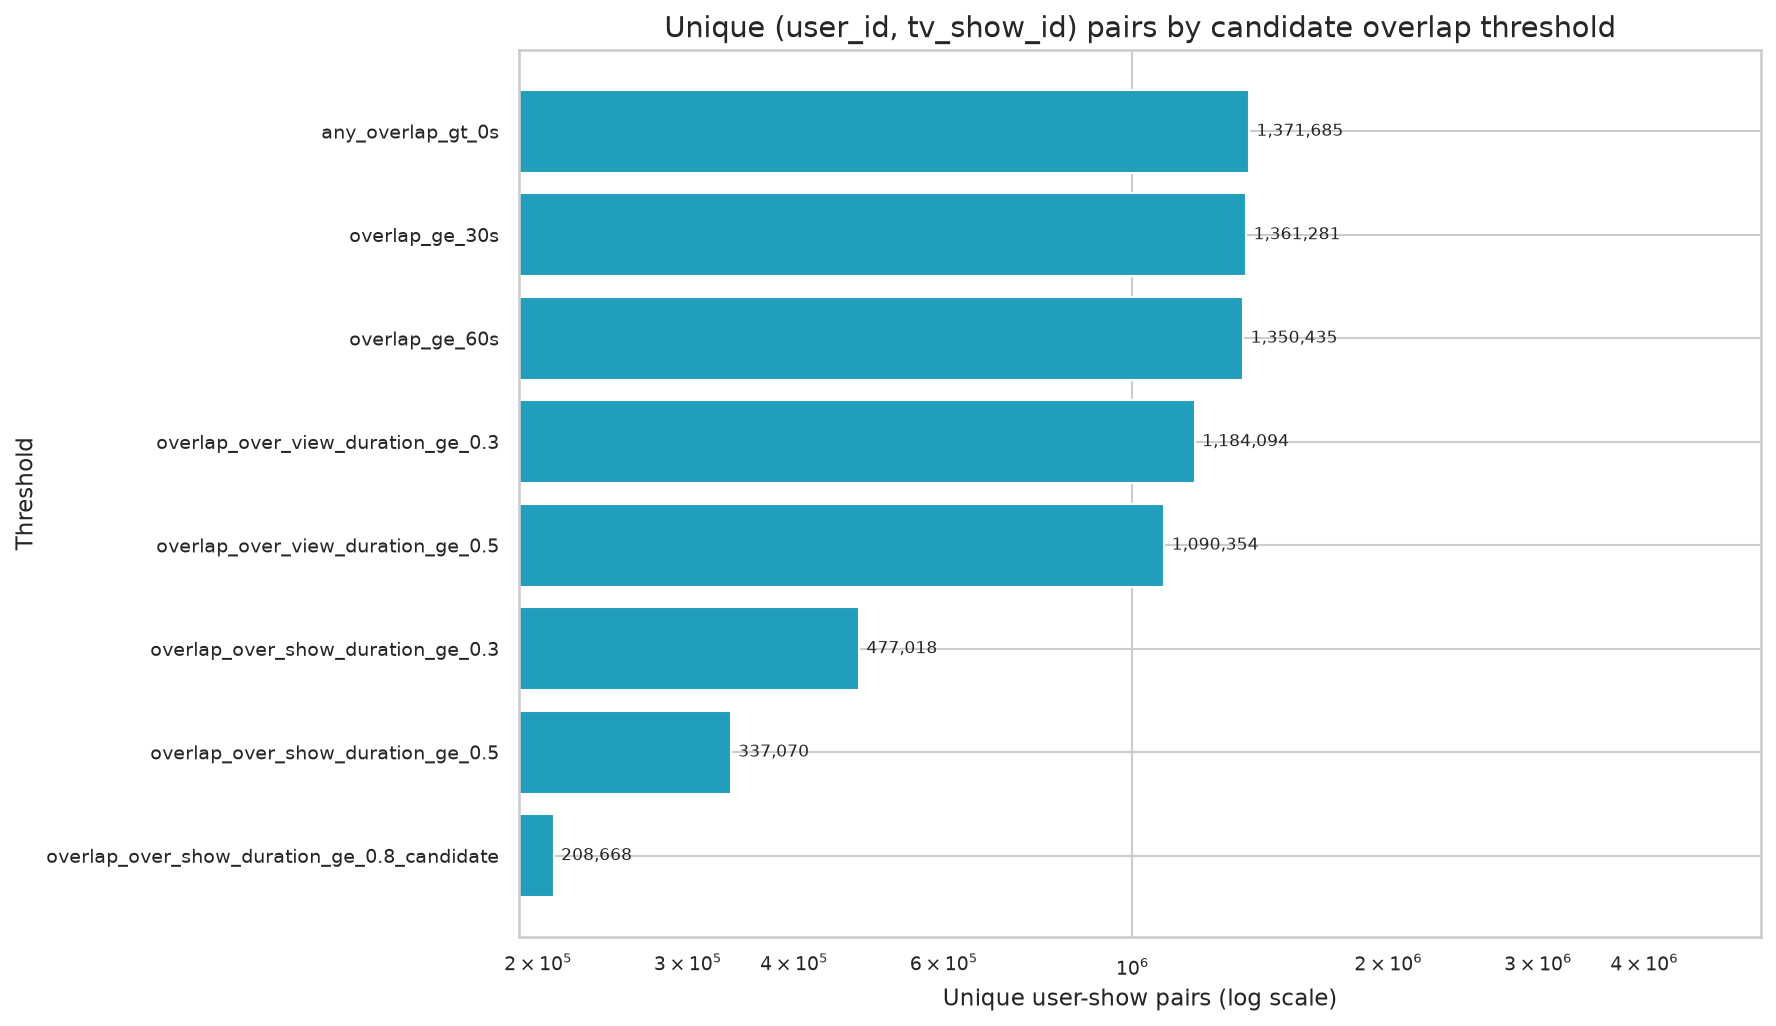

Saved 04_threshold_pair_counts.png


In [30]:
plot_thresholds = threshold_table.set_index("threshold")["n_user_show_pairs"].sort_values()
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(plot_thresholds.index, plot_thresholds.values, color="#219ebc")
ax.set_xscale("log")
ax.set_title("Unique (user_id, tv_show_id) pairs by candidate overlap threshold")
ax.set_xlabel("Unique user-show pairs (log scale)")
ax.set_ylabel("Threshold")
for bar, value in zip(bars, plot_thresholds.values):
    ax.text(value * 1.02, bar.get_y() + bar.get_height() / 2, f"{value:,}", va="center", fontsize=8)
ax.set_xlim(right=plot_thresholds.max() * 4)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_threshold_pair_counts.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 04_threshold_pair_counts.png")

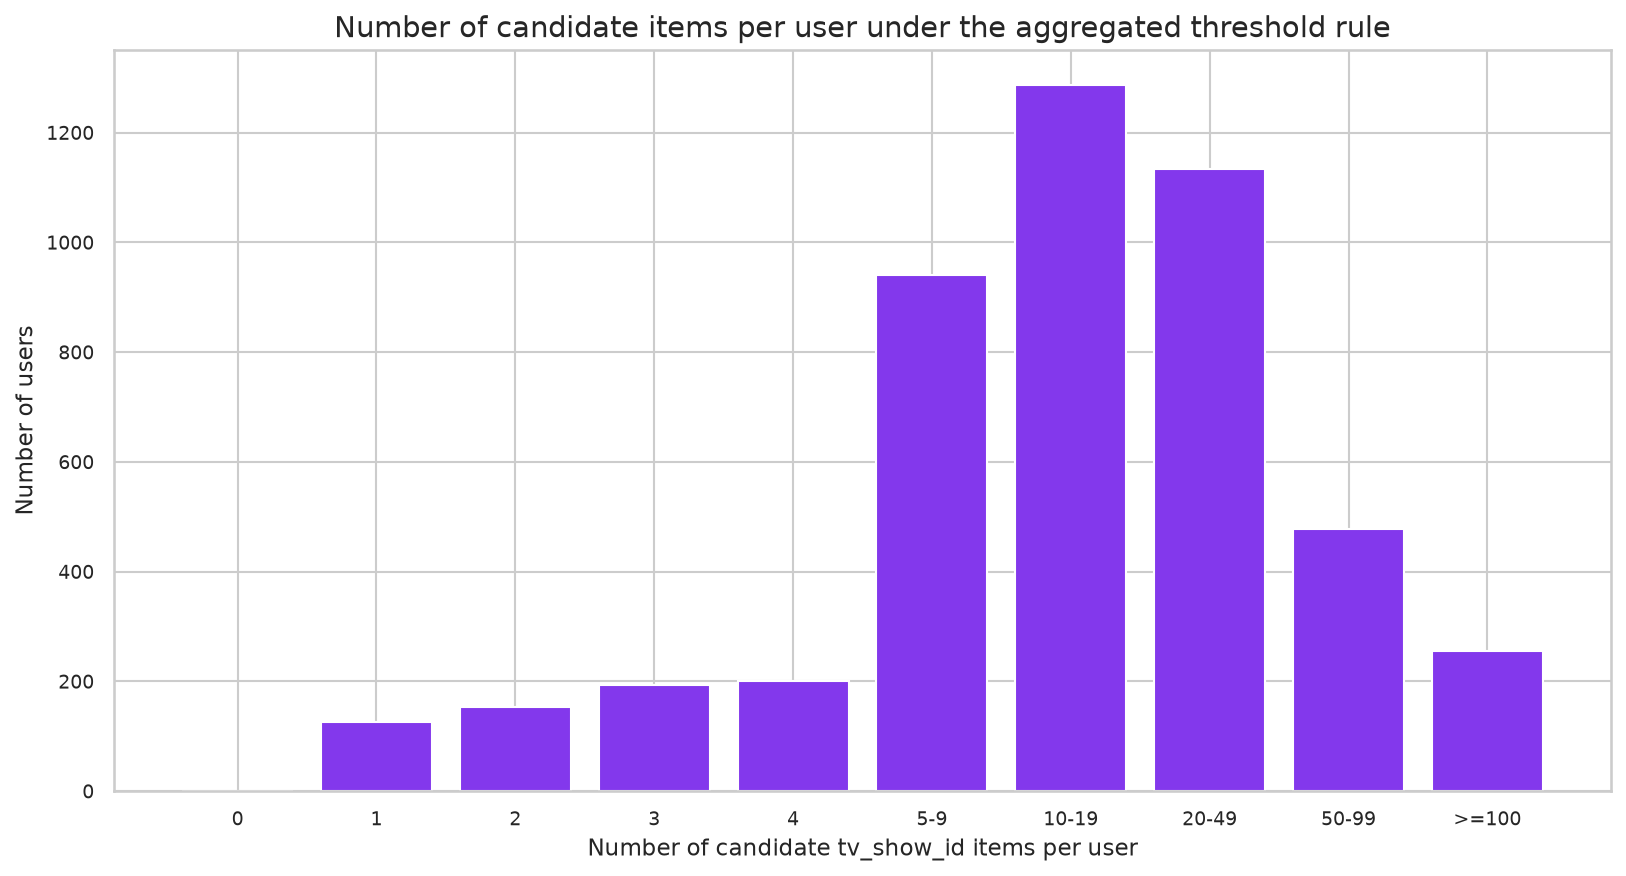

Saved 04_items_per_user_aggregated.png


In [31]:
item_bins = [0, 1, 2, 3, 4, 5, 10, 20, 50, 100, np.inf]
item_labels = ["0", "1", "2", "3", "4", "5-9", "10-19", "20-49", "50-99", ">=100"]
item_bin_counts = pd.cut(
    items_per_user, bins=item_bins, labels=item_labels, right=False
).value_counts().reindex(item_labels).fillna(0)
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(item_bin_counts.index.astype(str), item_bin_counts.values, color="#8338ec")
ax.set_title("Number of candidate items per user under the aggregated threshold rule")
ax.set_xlabel("Number of candidate tv_show_id items per user")
ax.set_ylabel("Number of users")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_items_per_user_aggregated.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 04_items_per_user_aggregated.png")

### Data hygiene

This check covers channel coverage of the view log, consistency between declared view duration and timestamps, and metadata coverage in labeled training schedule rows.

In [32]:
train_channel_ids = set(int(value) for value in train_schedule_core["channel_id"].unique())
view_channel_ids = set(int(value) for value in views_merged["vsetv_id"].unique())
channels_absent_from_schedule = int(len(view_channel_ids - train_channel_ids))

duration_sample = views_merged.sample(
    n=min(10_000, views_merged.shape[0]), random_state=SEED
)
duration_difference = (
    duration_sample["stop_time"] - duration_sample["start_time"]
).dt.total_seconds() - duration_sample["duration"]
duration_mismatch = int((duration_difference.abs() > 1).sum())

metadata_columns = [
    "tv_show_category", "tv_show_genre_1", "year_of_production", "director", "actors",
]
train_labeled_metadata = pd.concat(
    [
        schedules[role].loc[
            schedules[role]["tv_show_id"] != 0, metadata_columns
        ]
        for role in TRAIN_SCHEDULE_ROLES
    ],
    ignore_index=True,
)
hygiene_rows = [
    {
        "group": "channel coverage",
        "check": "views_merged vsetv_id absent from train_schedule_core.channel_id",
        "value": channels_absent_from_schedule,
        "detail": f"{len(view_channel_ids)} view channels; {len(train_channel_ids)} train channels",
    },
    {
        "group": "duration consistency",
        "check": "abs(duration - (stop_time - start_time)) > 1 s in 10k sample",
        "value": duration_mismatch,
        "detail": f"sample size {int(duration_sample.shape[0])}",
    },
]
for column in metadata_columns:
    values = train_labeled_metadata[column]
    if pd.api.types.is_numeric_dtype(values):
        non_empty = values.notna()
    else:
        non_empty = values.astype("string").str.strip().ne("").fillna(False)
    hygiene_rows.append({
        "group": "metadata coverage",
        "check": f"non-empty share: {column}",
        "value": float(non_empty.mean()) if len(non_empty) else float("nan"),
        "detail": f"labeled training rows: {int(train_labeled_metadata.shape[0])}",
    })

hygiene_table = pd.DataFrame(hygiene_rows)
display(hygiene_table)
print("Hygiene checks completed; values are shares for the metadata rows.")

,group,check,value,detail
0,channel coverage,views_merged vsetv_id absent from train_schedule_core.channel_id,5.000000,202 view channels; 404 train channels
1,duration consistency,abs(duration - (stop_time - start_time)) > 1 s in 10k sample,0.000000,sample size 10000
2,metadata coverage,non-empty share: tv_show_category,1.000000,labeled training rows: 237118
3,metadata coverage,non-empty share: tv_show_genre_1,0.954508,labeled training rows: 237118
4,metadata coverage,non-empty share: year_of_production,0.544860,labeled training rows: 237118
5,metadata coverage,non-empty share: director,0.864936,labeled training rows: 237118
6,metadata coverage,non-empty share: actors,0.868487,labeled training rows: 237118


Hygiene checks completed; values are shares for the metadata rows.


The labeled training schedule has complete tv_show_category coverage, tv_show_genre_1 is populated in about 95% of labeled rows, and director and actors are populated in about 86-87% of labeled rows. Metadata is therefore not limited to category and genre_1, although director and actors are less complete than category.

### Conclusion
The merged view log removes 96,572 rows (1.66%), reducing watched seconds from 8,619,215,224 to 8,503,411,121. For the control pair (user_id 13866173795451203812, tv_show_id 2400480), total_watched_s changed from 2,276,062 to 429,881 while total_show_duration_s stayed at 569,100. The full airing table has airings_exceeding_duration = 0.

Candidate view-program pairs: 7,631,029, of which 3,763,634 have a positive time overlap and tv_show_id != 0, covering 4,895 users, 4,363 shows, and 2,894,949 unique views. Overlaps are heavy-tailed: median 524 s, maximum 30,000 s.

When the threshold is tightened, the pair count changes as follows: any overlap > 0 s leaves 1,371,685 unique user-show pairs; >= 30 s leaves 1,361,281; >= 60 s leaves 1,350,435; overlap/view >= 0.5 leaves 1,090,354; overlap/show >= 0.5 leaves 337,070; and overlap/show >= 0.8 leaves 208,668. The relative threshold based on program duration is stricter than the absolute threshold in seconds.

At the airing level there are 3,014,129 rows, of which 611,760 are qualified. After aggregate ratio >= 0.8 and at least one qualified airing, 128,151 items remain for 4,768 users (median 14, mean 26.9, 90th percentile 72, maximum 253); 4,094 users have >= 5 items and 674 have < 5. Twelve test users have zero items and need a fallback, covered in section E. The hygiene check reports 5 view channels absent from the training schedule, no duration mismatch above 1 s in a 10,000-row sample, complete tv_show_category coverage, and 95.45% coverage for tv_show_genre_1 among labeled training rows.

## E. Test users and cold start

The public/private split of the test users is not documented in the materials used for this project and cannot be derived from the data. It cannot be derived from the data, and the nearly equal row counts of schedule11-20 and schedule21-30 reflect weekly grid volume rather than the test-user split. The exam cohort ranking uses only the returned public score (exam §10), so no modelling or selection decision depends on the assumed proportion.

In [33]:
if SUBMISSION_PATH is None:
    raise FileNotFoundError("submission.csv was not found under data_par")

submission = pd.read_csv(SUBMISSION_PATH, dtype=str)
submission.columns = [column.strip() for column in submission.columns]
submission["user_id"] = submission["user_id"].astype("uint64")
submission["tv_show_id"] = submission["tv_show_id"].fillna("")
slot_counts = submission["tv_show_id"].str.split().str.len()
test_users = submission["user_id"].drop_duplicates().to_numpy()

print("Submission path:", SUBMISSION_PATH)
print("Submission shape:", submission.shape)
print("Submission columns:", submission.columns.tolist())
print("Unique test user_id:", int(test_users.shape[0]))
print("Expected unique test user_id: 1260")
print("Submission slot-count distribution:")
display(slot_counts.value_counts().sort_index().rename("n_rows").to_frame())
display(submission.head(5), title="Submission head (non-ASCII)")

Submission path: /home/neferpitu/recsys/exam/Quize/data_par/submission.csv
Submission shape: (1260, 2)
Submission columns: ['user_id', 'tv_show_id']
Unique test user_id: 1260
Expected unique test user_id: 1260
Submission slot-count distribution:


,n_rows
tv_show_id,
5,1260


,user_id,tv_show_id
0,8377619604347126107,0 0 0 0 0
1,8381667675275833309,0 0 0 0 0
2,8387147770138767246,0 0 0 0 0
3,8397181578236218580,0 0 0 0 0
4,8404698046253197367,0 0 0 0 0


Test users fully absent from the training view log: 0
Test users with at least one aggregated-rule item: 1248
Test users with zero aggregated-rule items: 12
History length describe:


,history_items
count,1260.000000
mean,28.907143
std,34.209792
min,0.000000
50%,17.000000
90%,72.100000
95%,109.050000
99%,159.410000
max,253.000000


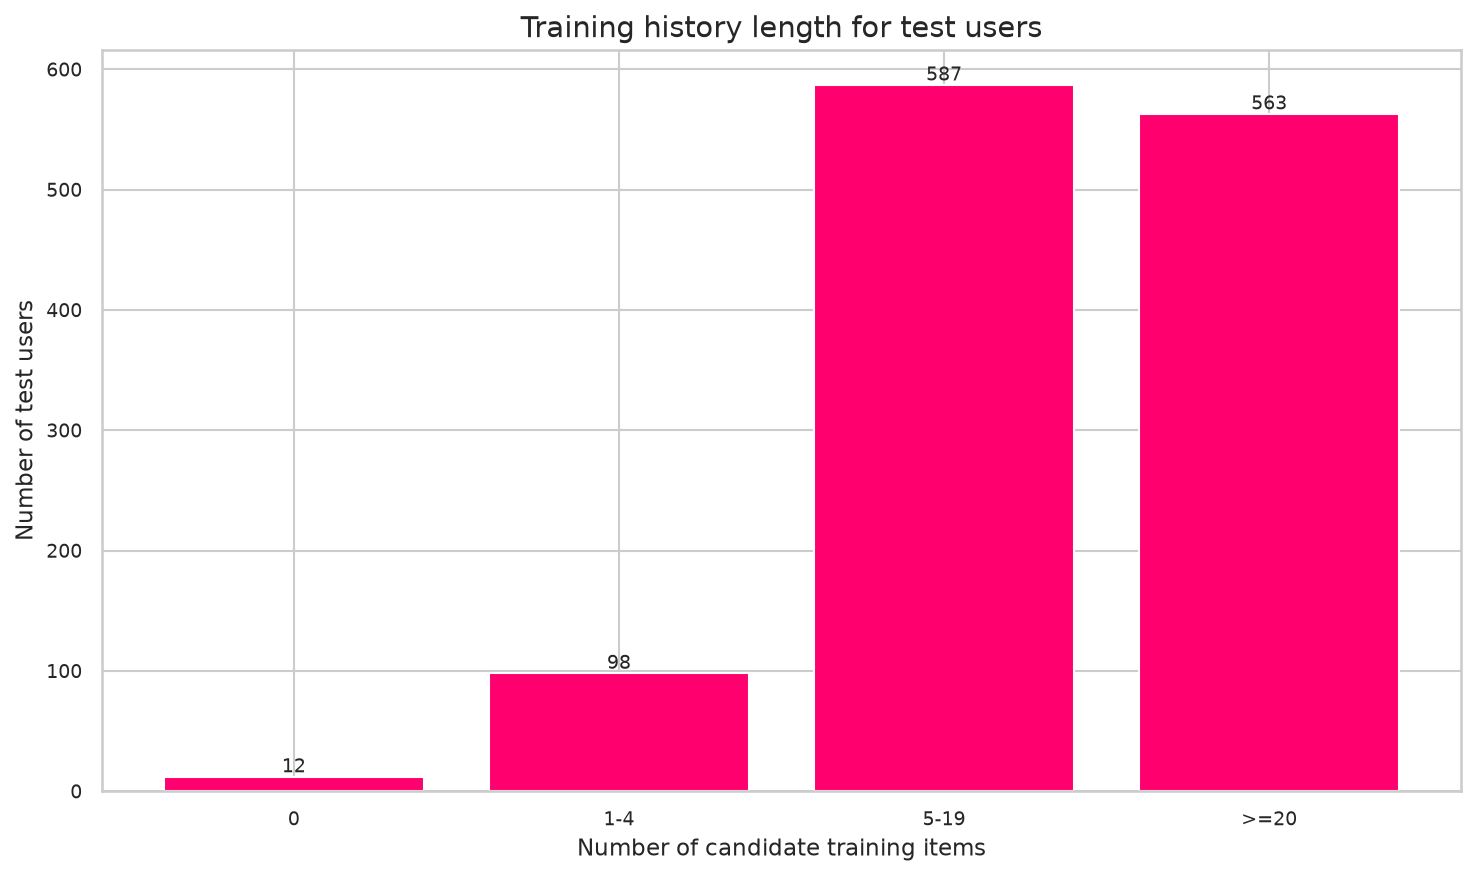

Saved 05_test_user_history_bins.png


,n_test_users
0,12
1-4,98
5-19,587
>=20,563


In [34]:
view_users = pd.unique(views_merged["user_id"].to_numpy())
absent_from_view_log = int((~np.isin(test_users, view_users)).sum())
print("Test users fully absent from the training view log:", absent_from_view_log)

item_counts_by_user = train_items.groupby("user_id").size()
history_length = item_counts_by_user.reindex(test_users, fill_value=0).astype(int)
print("Test users with at least one aggregated-rule item:", int((history_length > 0).sum()))
print("Test users with zero aggregated-rule items:", int((history_length == 0).sum()))
print("History length describe:")
display(history_length.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("history_items"))

history_bins = [-1, 0, 4, 19, np.inf]
history_labels = ["0", "1-4", "5-19", ">=20"]
history_binned = pd.cut(
    history_length, bins=history_bins, labels=history_labels
).value_counts().reindex(history_labels).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(history_binned.index.astype(str), history_binned.values, color="#ff006e")
ax.set_title("Training history length for test users")
ax.set_xlabel("Number of candidate training items")
ax.set_ylabel("Number of test users")
for index, value in enumerate(history_binned.values):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_test_user_history_bins.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 05_test_user_history_bins.png")
display(history_binned.to_frame("n_test_users"))

### Conclusion
The submission contains 1,260 test users x 5 slots (all current values are 0 0 0 0 0). None of the test users is completely absent from the merged view log. After applying the aggregated rule, 1,248 users have at least one history item and 12 users have zero items, so a fallback is still required.

History length distribution: median 17, mean 28.9, 90th percentile 72.1, 95th percentile 109.1, maximum 253. By bins: 0 - 12, 1-4 - 98, 5-19 - 587, >= 20 - 563 users. In total, 110 users (8.7%) have fewer than 5 items.

## F. Popularity and catalogue coverage

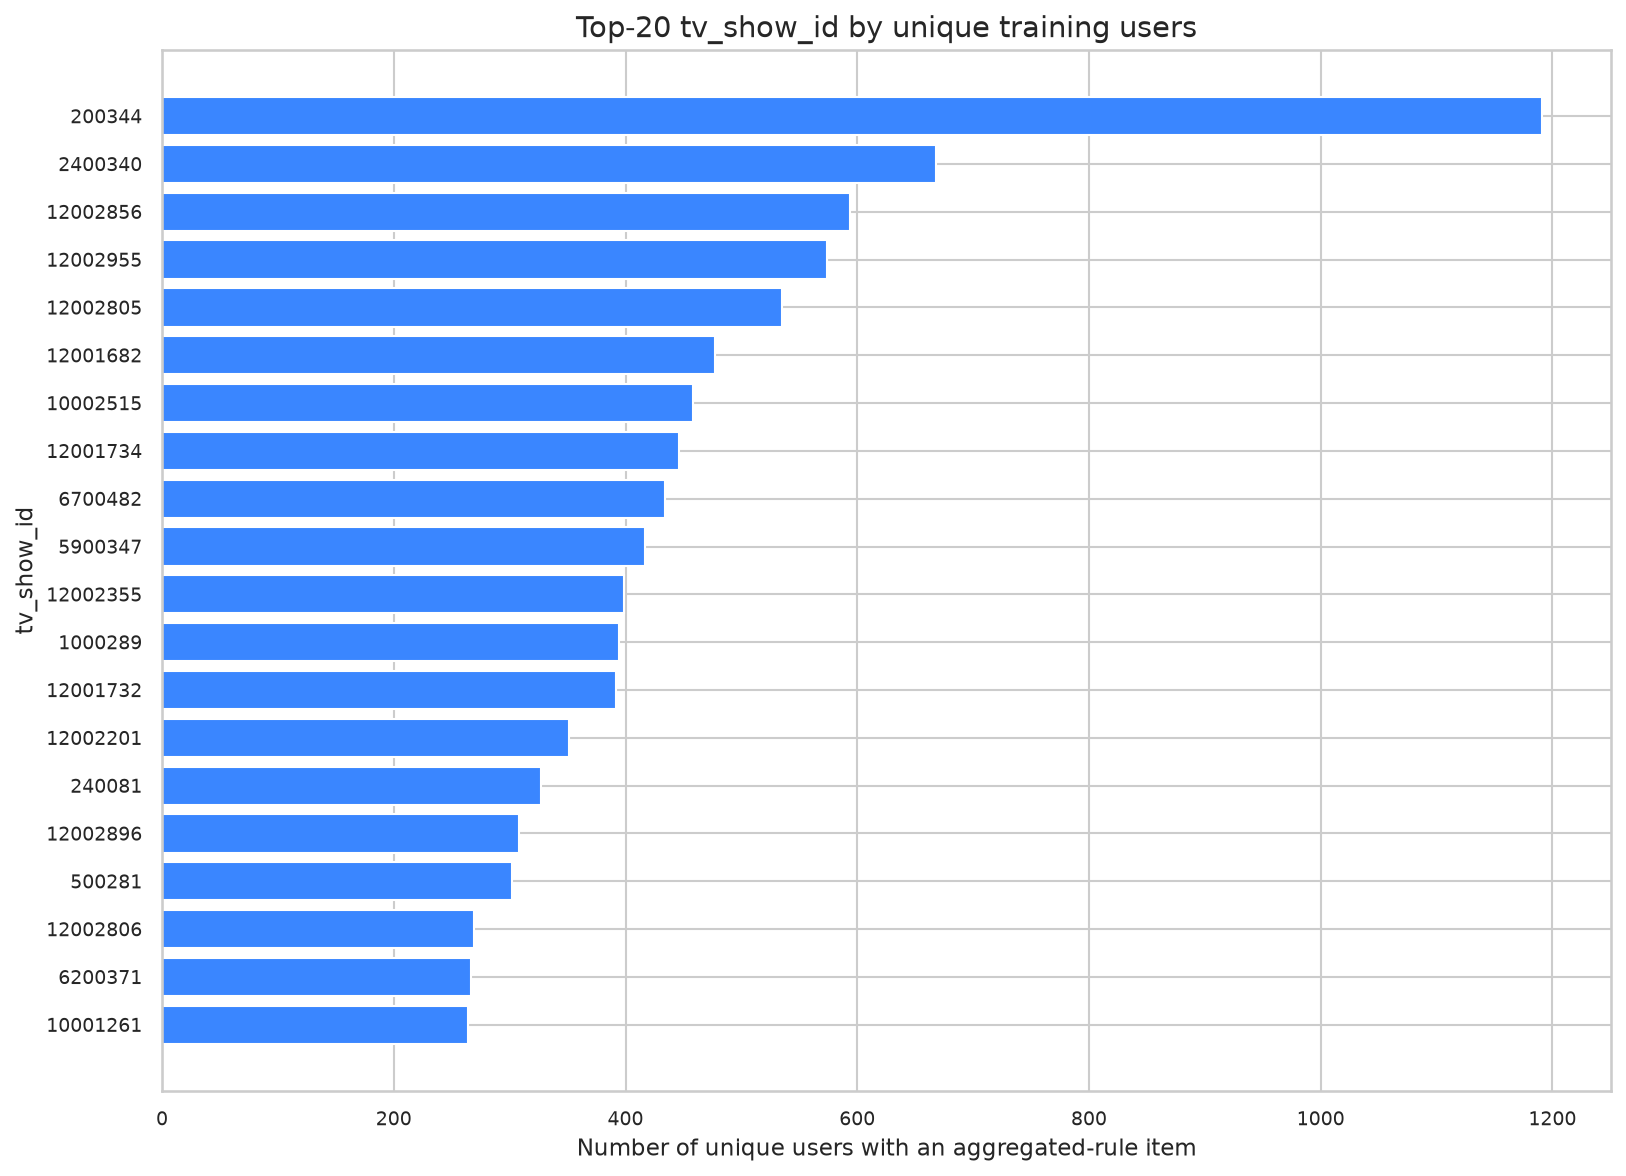

Saved 06_top20_shows.png | popular shows: 20


In [35]:
show_user_counts = train_items.groupby("tv_show_id")["user_id"].nunique().sort_values(ascending=False)
top_shows = show_user_counts.head(20).sort_values()
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(top_shows.index.astype(str), top_shows.values, color="#3a86ff")
ax.set_title("Top-20 tv_show_id by unique training users")
ax.set_xlabel("Number of unique users with an aggregated-rule item")
ax.set_ylabel("tv_show_id")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_top20_shows.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 06_top20_shows.png | popular shows:", int(top_shows.shape[0]))

,program_share,n_programs,share_of_user_show_items
0,0.01,39,0.104385
1,0.10,385,0.419006


Total catalog shows in aggregated-rule items: 3849
Total user-show interaction items: 128151


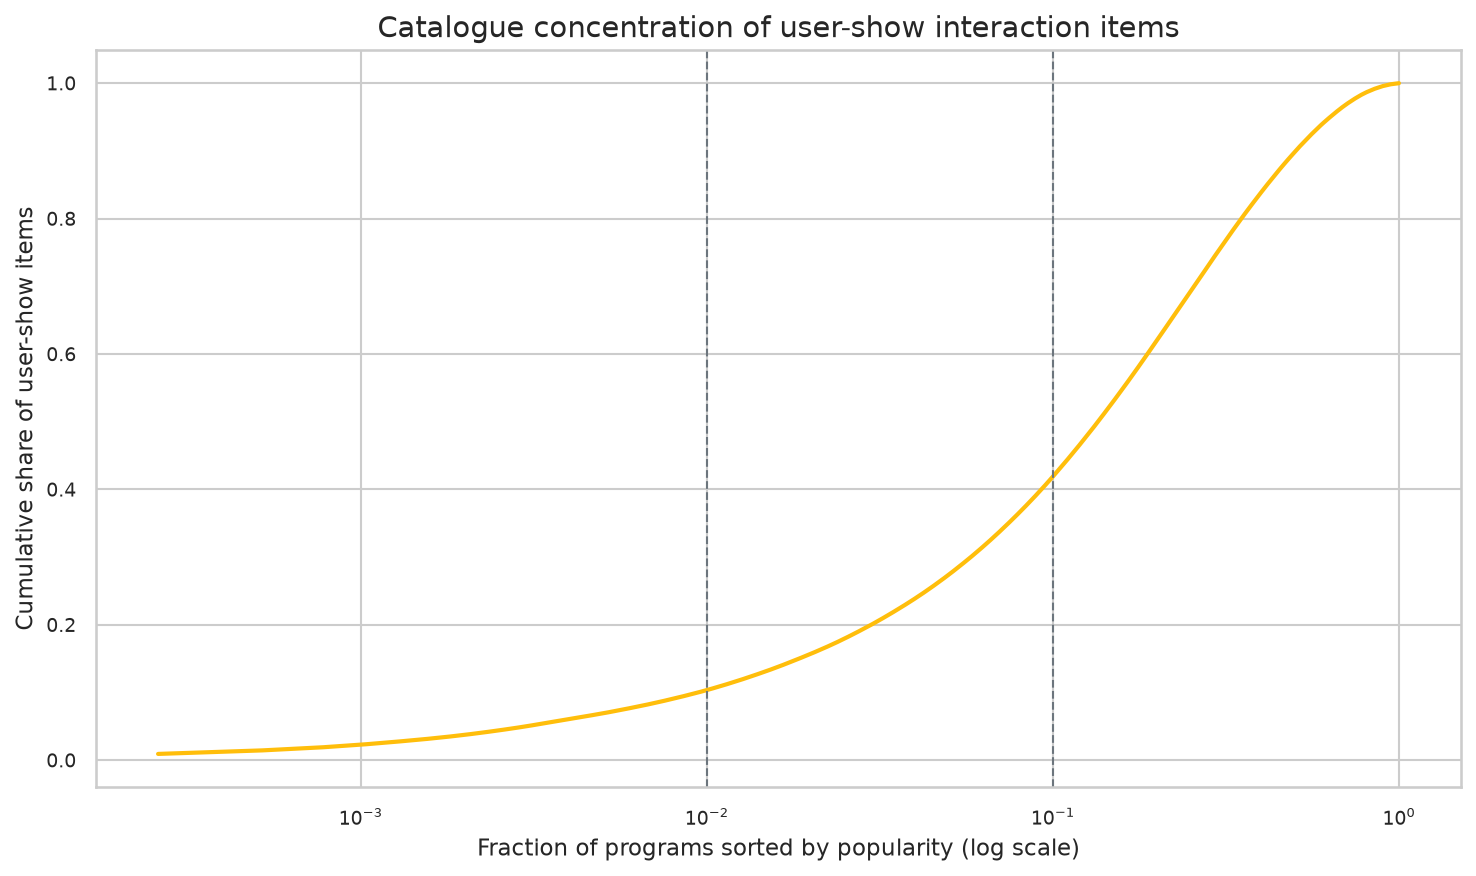

Saved 06_catalogue_concentration.png


In [36]:
sorted_show_user_counts = show_user_counts.sort_values(ascending=False).to_numpy()
total_interactions = sorted_show_user_counts.sum()
n_shows = sorted_show_user_counts.shape[0]
concentration_rows = []
for share in [0.01, 0.10]:
    k = max(1, int(np.ceil(share * n_shows)))
    covered = sorted_show_user_counts[:k].sum()
    concentration_rows.append({
        "program_share": share,
        "n_programs": k,
        "share_of_user_show_items": covered / total_interactions,
    })
concentration = pd.DataFrame(concentration_rows)
display(concentration)
print("Total catalog shows in aggregated-rule items:", int(n_shows))
print("Total user-show interaction items:", int(total_interactions))

cumulative_share = np.cumsum(sorted_show_user_counts) / total_interactions
program_fraction = np.arange(1, n_shows + 1) / n_shows
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(program_fraction, cumulative_share, color="#ffbe0b", linewidth=2)
ax.set_xscale("log")
ax.set_title("Catalogue concentration of user-show interaction items")
ax.set_xlabel("Fraction of programs sorted by popularity (log scale)")
ax.set_ylabel("Cumulative share of user-show items")
for row in concentration_rows:
    ax.axvline(row["program_share"], linestyle="--", color="#6c757d", linewidth=1)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_catalogue_concentration.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 06_catalogue_concentration.png")

,metric,value
0,train_schedule_nonzero_show_ids,8234.000000
1,test_schedule_nonzero_show_ids,6636.000000
2,show_ids_in_both_train_and_test_schedule,5199.000000
3,show_ids_only_in_train_schedule,3035.000000
4,show_ids_only_in_test_schedule,1437.000000
5,test_show_ids_never_in_training_view_log,3523.000000
6,test_show_ids_never_in_training_view_log_share,0.530892


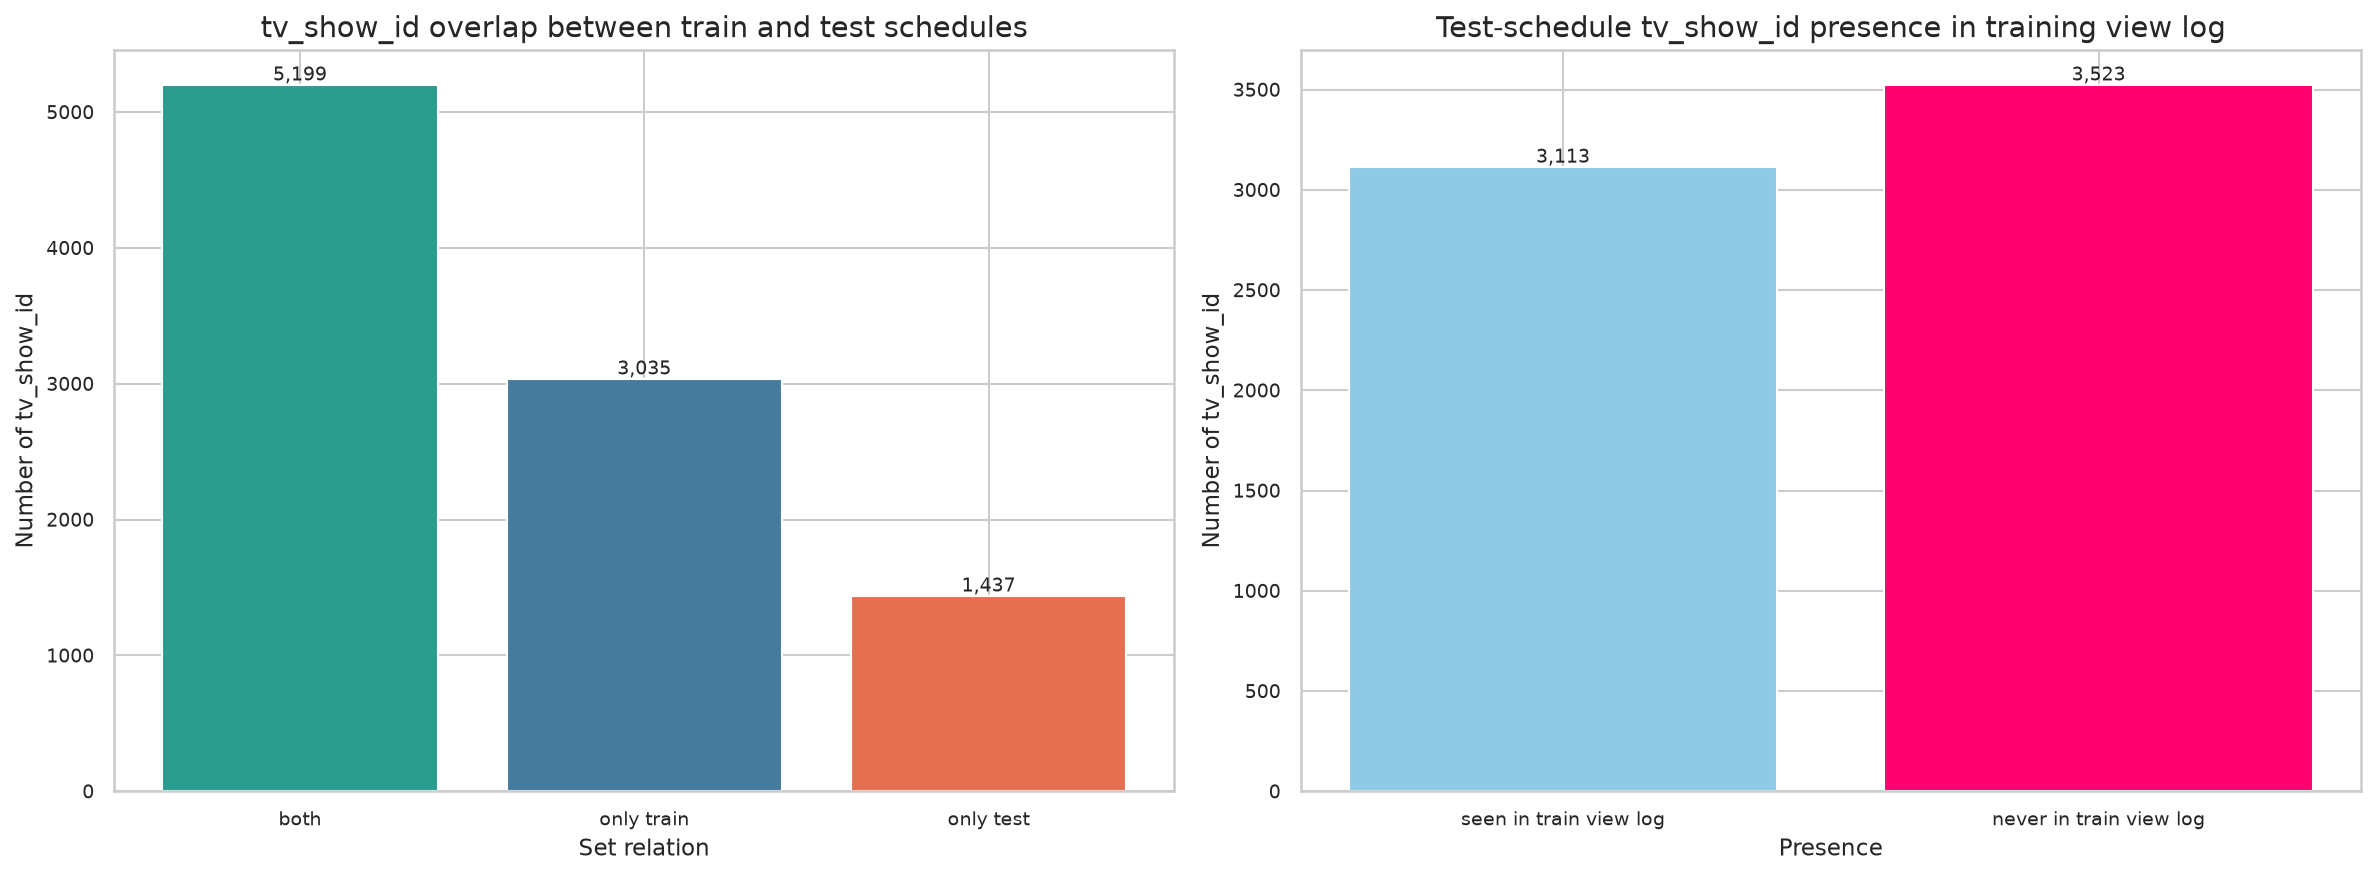

Saved 06_train_test_show_overlap.png
Test schedule is used only as a tv_show_id catalogue reference in this section.


In [37]:
train_show_ids = np.unique(
    pd.concat([schedules[role]["tv_show_id"] for role in TRAIN_SCHEDULE_ROLES], ignore_index=True)
    .loc[lambda values: values != 0]
    .to_numpy()
)
test_schedule = schedules[TEST_SCHEDULE_ROLE]
test_show_ids = np.unique(
    test_schedule.loc[test_schedule["tv_show_id"] != 0, "tv_show_id"].to_numpy()
)
train_view_show_ids = np.unique(pair["tv_show_id"].to_numpy())

both_show_ids = np.intersect1d(train_show_ids, test_show_ids)
only_train_show_ids = np.setdiff1d(train_show_ids, test_show_ids)
only_test_show_ids = np.setdiff1d(test_show_ids, train_show_ids)
test_never_in_train_view = np.setdiff1d(test_show_ids, train_view_show_ids)

overlap_summary = pd.DataFrame([
    {"metric": "train_schedule_nonzero_show_ids", "value": int(train_show_ids.shape[0])},
    {"metric": "test_schedule_nonzero_show_ids", "value": int(test_show_ids.shape[0])},
    {"metric": "show_ids_in_both_train_and_test_schedule", "value": int(both_show_ids.shape[0])},
    {"metric": "show_ids_only_in_train_schedule", "value": int(only_train_show_ids.shape[0])},
    {"metric": "show_ids_only_in_test_schedule", "value": int(only_test_show_ids.shape[0])},
    {"metric": "test_show_ids_never_in_training_view_log", "value": int(test_never_in_train_view.shape[0])},
    {"metric": "test_show_ids_never_in_training_view_log_share", "value": float(test_never_in_train_view.shape[0] / test_show_ids.shape[0])},
])
display(overlap_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
set_labels = ["both", "only train", "only test"]
set_values = [both_show_ids.shape[0], only_train_show_ids.shape[0], only_test_show_ids.shape[0]]
axes[0].bar(set_labels, set_values, color=["#2a9d8f", "#457b9d", "#e76f51"])
axes[0].set_title("tv_show_id overlap between train and test schedules")
axes[0].set_xlabel("Set relation")
axes[0].set_ylabel("Number of tv_show_id")

seen_test = test_show_ids.shape[0] - test_never_in_train_view.shape[0]
unseen_test = test_never_in_train_view.shape[0]
axes[1].bar(["seen in train view log", "never in train view log"], [seen_test, unseen_test],
            color=["#8ecae6", "#ff006e"])
axes[1].set_title("Test-schedule tv_show_id presence in training view log")
axes[1].set_xlabel("Presence")
axes[1].set_ylabel("Number of tv_show_id")
for ax in axes:
    for bar in ax.patches:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{int(bar.get_height()):,}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_train_test_show_overlap.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 06_train_test_show_overlap.png")
print("Test schedule is used only as a tv_show_id catalogue reference in this section.")

In [38]:
train2_show_ids = np.unique(
    schedules["train_schedule_2"]
    .loc[schedules["train_schedule_2"]["tv_show_id"] != 0, "tv_show_id"]
    .to_numpy()
)
test_catalogue_show_ids = np.unique(
    schedules[TEST_SCHEDULE_ROLE]
    .loc[schedules[TEST_SCHEDULE_ROLE]["tv_show_id"] != 0, "tv_show_id"]
    .to_numpy()
)
train2_test_both = np.intersect1d(train2_show_ids, test_catalogue_show_ids)
train2_test_only_train2 = np.setdiff1d(train2_show_ids, test_catalogue_show_ids)
train2_test_only_test = np.setdiff1d(test_catalogue_show_ids, train2_show_ids)
train2_view_show_ids = np.unique(pair["tv_show_id"].to_numpy())
test_never_in_train_view = np.setdiff1d(test_catalogue_show_ids, train2_view_show_ids)

train2_test_summary = pd.DataFrame([
    {"metric": "train_schedule_2_nonzero_show_ids", "value": int(train2_show_ids.shape[0])},
    {"metric": "test_schedule_nonzero_show_ids", "value": int(test_catalogue_show_ids.shape[0])},
    {"metric": "show_ids_in_both_train2_and_test", "value": int(train2_test_both.shape[0])},
    {"metric": "show_ids_only_in_train2", "value": int(train2_test_only_train2.shape[0])},
    {"metric": "show_ids_only_in_test", "value": int(train2_test_only_test.shape[0])},
    {"metric": "test_show_ids_never_in_training_view_log", "value": int(test_never_in_train_view.shape[0])},
])
display(train2_test_summary)
print("Test schedule is used only as a tv_show_id catalogue reference in this check.")

,metric,value
0,train_schedule_2_nonzero_show_ids,6363
1,test_schedule_nonzero_show_ids,6636
2,show_ids_in_both_train2_and_test,4389
3,show_ids_only_in_train2,1974
4,show_ids_only_in_test,2247
5,test_show_ids_never_in_training_view_log,3523


Test schedule is used only as a tv_show_id catalogue reference in this check.


In [39]:
show_user_counts = train_items.groupby("tv_show_id")["user_id"].nunique().sort_values(ascending=False)
top10_show_ids = show_user_counts.head(10)
training_schedule_labeled = pd.concat(
    [schedules[role] for role in TRAIN_SCHEDULE_ROLES], ignore_index=True
)
training_schedule_labeled = training_schedule_labeled.loc[
    training_schedule_labeled["tv_show_id"] != 0
]
top10_rows = []
for rank, (show_id, n_users) in enumerate(top10_show_ids.items(), start=1):
    examples = training_schedule_labeled.loc[
        training_schedule_labeled["tv_show_id"] == show_id
    ]
    title = examples["tv_show_title"].value_counts().index[0] if len(examples) else ""
    category = examples["tv_show_category"].value_counts().index[0] if len(examples) else ""
    top10_rows.append({
        "rank": rank,
        "tv_show_id": int(show_id),
        "n_users": int(n_users),
        "most_frequent_title": title,
        "most_frequent_category": category,
    })
top10_table = pd.DataFrame(top10_rows)
display(top10_table)
for show_id in [2400480, 2400467]:
    position = int(np.where(show_user_counts.index == show_id)[0][0]) + 1 if show_id in show_user_counts.index else None
    print(f"tv_show_id {show_id}: rank={position}, n_users={int(show_user_counts.get(show_id, 0))}")


,rank,tv_show_id,n_users,most_frequent_title,most_frequent_category
0,1,200344,1191,'Чистоnews'.,Развлечения
1,2,2400340,668,Служба розыска детей.,Инфо
2,3,12002856,594,М/с 'Элвиннн!!! и бурундуки'.,Детям
3,4,12002955,574,М/с 'Свинка Пеппа'.,Детям
4,5,12002805,535,М/с 'Моланг'.,Детям
5,6,12001682,477,М/с 'Губка Боб Квадратные Штаны'.,Детям
6,7,10002515,458,"Т/с 'Мамочки', 1 сезон, 19 и 20 с.",Сериалы
7,8,12001734,446,М/с 'Волшебные покровители'.,Детям
8,9,6700482,434,Секретные материалы.,Другое
9,10,5900347,417,'Деньги'.,Инфо


tv_show_id 2400480: rank=75, n_users=158
tv_show_id 2400467: rank=25, n_users=238


### Conclusion
tv_show_id 200344 is the leader by the number of unique training users with an aggregated-rule item, with 1,191 users; tv_show_id 2400340 is second with 668 users. Popularity is extremely skewed: the top 1% of shows (39 programs) accounts for 10.4% of all user-show items, while the top 10% (385 programs) accounts for 41.9%. In total, 3,849 shows appear in aggregated items, with 128,151 user-show items; about 3,464 shows fall outside the top 10%.

The train_schedule_2 versus test catalogue comparison contains 6,363 and 6,636 nonzero show ids respectively: 4,389 appear in both, 1,974 only in train_schedule_2, and 2,247 only in the test catalogue. In addition, 3,523 test show ids never appear in the training view log.

## G. Repeats and Temporal Stability

This section compares the two training windows 11-20 and 21-30. Personal repeats are measured on the 1260 test users. Popularity is measured by distinct users with an aggregated-rule item.

In [40]:
items_11_20 = items_for_weeks(pair, views_merged, range(11, 21))
items_21_30 = items_for_weeks(pair, views_merged, range(21, 31))
print("Aggregated-rule items in weeks 11-20:", int(items_11_20.shape[0]),
      "| users:", int(items_11_20["user_id"].nunique()),
      "| shows:", int(items_11_20["tv_show_id"].nunique()))
print("Aggregated-rule items in weeks 21-30:", int(items_21_30.shape[0]),
      "| users:", int(items_21_30["user_id"].nunique()),
      "| shows:", int(items_21_30["tv_show_id"].nunique()))

Aggregated-rule items in weeks 11-20: 54294 | users: 4610 | shows: 2480
Aggregated-rule items in weeks 21-30: 97280 | users: 4504 | shows: 2843


In [41]:
test_user_set = set(int(user) for user in test_users)
target_window = items_21_30[items_21_30["user_id"].isin(test_user_set)].copy()
first_window_pairs = items_11_20[
    items_11_20["user_id"].isin(test_user_set)
][["user_id", "tv_show_id"]].drop_duplicates()
first_window_pairs["seen_in_11_20"] = True
target_window = target_window.merge(
    first_window_pairs, on=["user_id", "tv_show_id"], how="left"
)
target_window["seen_in_11_20"] = target_window["seen_in_11_20"].fillna(False).astype(bool)
target_window["repeat_airings"] = (
    target_window["qualified_airings"] * target_window["seen_in_11_20"].astype(int)
)

repeat_by_user = target_window.groupby("user_id").agg(
    target_items=("tv_show_id", "size"),
    target_airings=("qualified_airings", "sum"),
    repeat_items=("seen_in_11_20", "sum"),
    repeat_airings=("repeat_airings", "sum"),
)
repeat_by_user["repeat_share_airings"] = (
    repeat_by_user["repeat_airings"] / repeat_by_user["target_airings"].replace(0, np.nan)
)
repeat_by_user["repeat_share_items"] = (
    repeat_by_user["repeat_items"] / repeat_by_user["target_items"].replace(0, np.nan)
)
repeat_share_airings = repeat_by_user["repeat_share_airings"].dropna()

print("Test users with at least one item in weeks 21-30:", int(repeat_by_user.shape[0]))
print("Mean repeat share of target airings:", round(float(repeat_share_airings.mean()), 6))
print("Median repeat share of target airings:", round(float(repeat_share_airings.median()), 6))
display(repeat_by_user.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

Test users with at least one item in weeks 21-30: 1214
Mean repeat share of target airings: 0.067541
Median repeat share of target airings: 0.0


,target_items,target_airings,repeat_items,repeat_airings,repeat_share_airings,repeat_share_items
count,1214.000000,1214.000000,1214.000000,1214.000000,1214.000000,1214.000000
mean,22.771829,41.443163,0.806425,5.121087,0.067541,0.036695
std,31.503226,74.012786,1.724540,27.377686,0.154378,0.080441
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,11.000000,15.000000,0.000000,0.000000,0.000000,0.000000
90%,61.000000,110.700000,2.000000,10.000000,0.249286,0.111111
95%,97.700000,185.000000,4.000000,20.350000,0.439366,0.200000
99%,140.870000,346.010000,8.000000,88.700000,0.766586,0.375000
max,248.000000,943.000000,17.000000,575.000000,0.928571,0.750000


In [42]:
popularity_11_20 = items_11_20.groupby("tv_show_id")["user_id"].nunique().sort_values(ascending=False)
popularity_21_30 = items_21_30.groupby("tv_show_id")["user_id"].nunique().sort_values(ascending=False)
top_overlap_rows = []
for top_n in [5, 20, 100]:
    first_set = set(popularity_11_20.head(top_n).index)
    second_set = set(popularity_21_30.head(top_n).index)
    intersection = first_set & second_set
    union = first_set | second_set
    top_overlap_rows.append({
        "top_n": top_n,
        "overlap_count": len(intersection),
        "overlap_share_of_top_n": len(intersection) / top_n,
        "jaccard": len(intersection) / len(union) if union else np.nan,
    })
top_overlap = pd.DataFrame(top_overlap_rows)
display(top_overlap)

,top_n,overlap_count,overlap_share_of_top_n,jaccard
0,5,1,0.20,0.111111
1,20,13,0.65,0.481481
2,100,50,0.50,0.333333


In [43]:
weeks = list(range(11, 31))
weekly_top10 = {}
for week in weeks:
    weekly_items = items_for_weeks(pair, views_merged, [week])
    weekly_counts = weekly_items.groupby("tv_show_id")["user_id"].nunique().sort_values(ascending=False)
    weekly_top10[week] = set(weekly_counts.head(10).index)

lag_rows = []
for lag in range(1, 9):
    overlaps = []
    for week in weeks:
        if week + lag in weekly_top10:
            overlaps.append(len(weekly_top10[week] & weekly_top10[week + lag]) / 10.0)
    lag_rows.append({
        "lag_weeks": lag,
        "mean_top10_overlap": float(np.mean(overlaps)) if overlaps else np.nan,
        "n_pairs": len(overlaps),
    })
top10_stability = pd.DataFrame(lag_rows)
display(top10_stability)

,lag_weeks,mean_top10_overlap,n_pairs
0,1,0.784211,19
1,2,0.744444,18
2,3,0.723529,17
3,4,0.712500,16
4,5,0.693333,15
5,6,0.671429,14
6,7,0.676923,13
7,8,0.675000,12


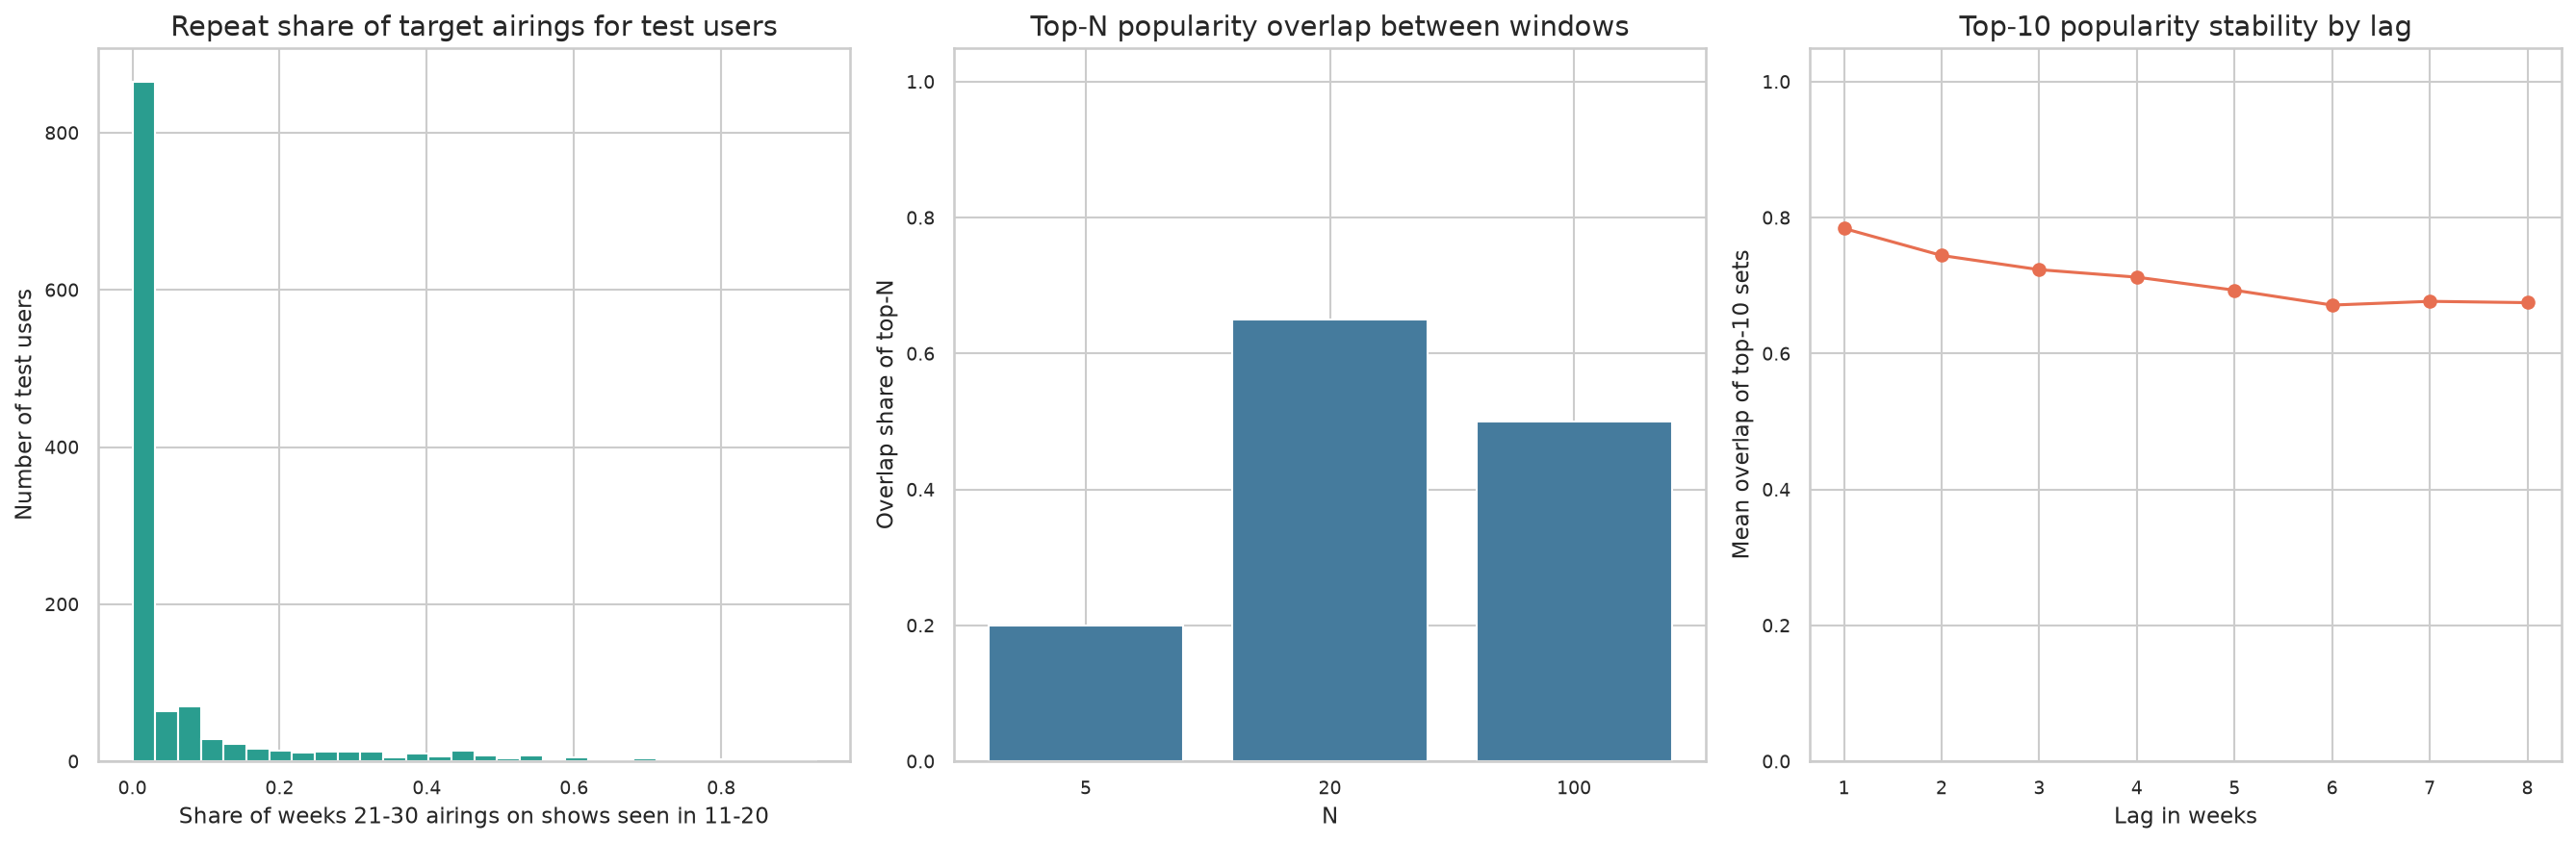

Saved 17_repeats.png


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].hist(repeat_share_airings.to_numpy(), bins=30, color="#2a9d8f")
axes[0].set_title("Repeat share of target airings for test users")
axes[0].set_xlabel("Share of weeks 21-30 airings on shows seen in 11-20")
axes[0].set_ylabel("Number of test users")

axes[1].bar(
    top_overlap["top_n"].astype(str),
    top_overlap["overlap_share_of_top_n"],
    color="#457b9d",
)
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Top-N popularity overlap between windows")
axes[1].set_xlabel("N")
axes[1].set_ylabel("Overlap share of top-N")

axes[2].plot(
    top10_stability["lag_weeks"],
    top10_stability["mean_top10_overlap"],
    marker="o",
    color="#e76f51",
)
axes[2].set_ylim(0, 1.05)
axes[2].set_title("Top-10 popularity stability by lag")
axes[2].set_xlabel("Lag in weeks")
axes[2].set_ylabel("Mean overlap of top-10 sets")

fig.tight_layout()
fig.savefig(FIG_DIR / "17_repeats.png", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved 17_repeats.png")

### Conclusion
Repeat consumption of content is weakly expressed: among test users, the mean share of weeks 21-30 airings on shows seen in weeks 11-20 is 6.75%, and the median is zero; at the user-show level the mean share is 3.67%. The 90th percentile reaches 24.9%, the 99th percentile 76.7%, and the maximum 92.9%.

Popularity overlap between long windows is unstable at the very top: top-5 overlap is 1 of 5 (20%, Jaccard 0.111); top-20 overlap is 13 of 20 (65%, Jaccard 0.481); top-100 overlap is 50 of 100 (50%, Jaccard 0.333). Short-term stability is higher: mean top-10 overlap at a one-week lag is 0.784 and decreases with lag, reaching 0.675 at an eight-week lag.

## H. Validation Split and Metric Baselines

Preliminary section. These baselines apply no candidate-pool restriction, rank personal history by qualified_airings and evaluate 1,214 test users. The reference validation protocol is outputs/evaluation/evaluation.ipynb; its numbers differ because of the candidate pool, the ranking key and the user group.

Validation uses weeks 11-20 as the training window and weeks 21-30 as the target window. Evaluation is restricted to test users with at least one aggregated-rule item in the target window. The three reference baselines are built only from weeks 11-20: global popularity from 11-20, recent popularity from 17-20, and personal history from 11-20. No test-week behaviour is used.

In [45]:
def average_precision_at_k(recommended, relevant, k=5):
    relevant = set(relevant)
    if not relevant:
        return np.nan
    recommended = list(recommended)[:k]
    hits = 0
    precision_sum = 0.0
    for rank, item in enumerate(recommended, start=1):
        if item in relevant:
            hits += 1
            precision_sum += hits / rank
    return precision_sum / min(len(relevant), k)


toy_recommended = [101, 102, 103, 104, 105]
toy_relevant = {101, 103, 106}
toy_ap = average_precision_at_k(toy_recommended, toy_relevant, k=5)
toy_expected = (1 / 1 + 2 / 3) / 3
assert np.isclose(toy_ap, toy_expected), (toy_ap, toy_expected)
assert np.isnan(average_precision_at_k([1, 2], set(), k=5))
print("AP@5 unit test passed:", round(float(toy_ap), 6), "expected:", round(float(toy_expected), 6))

AP@5 unit test passed: 0.555556 expected: 0.555556


In [46]:
validation_users = np.intersect1d(test_users, items_21_30["user_id"].unique())
print("Validation users with target items:", int(validation_users.shape[0]))
target_items_per_user = items_21_30[
    items_21_30["user_id"].isin(validation_users)
].groupby("user_id").size()
print("Target items per validation user:")
display(target_items_per_user.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("target_items"))

Validation users with target items: 1214
Target items per validation user:


,target_items
count,1214.000000
mean,22.771829
std,31.503226
min,1.000000
50%,11.000000
90%,61.000000
95%,97.700000
99%,140.870000
max,248.000000


In [47]:
global_top5 = items_11_20.groupby("tv_show_id")["user_id"].nunique().sort_values(
    ascending=False
).head(5).index.tolist()

items_17_20 = items_for_weeks(pair, views_merged, range(17, 21))
recent_top5 = items_17_20.groupby("tv_show_id")["user_id"].nunique().sort_values(
    ascending=False
).head(5).index.tolist()

history_sorted = items_11_20.sort_values(
    ["user_id", "qualified_airings", "tv_show_id"],
    ascending=[True, False, True],
)
personal_top5 = history_sorted.groupby("user_id").head(5).groupby("user_id")["tv_show_id"].agg(list)
personal_top5_map = {int(user): [int(show) for show in shows] for user, shows in personal_top5.items()}
relevance_map = {
    int(user): set(int(show) for show in shows)
    for user, shows in items_21_30.groupby("user_id")["tv_show_id"].agg(set).items()
}
validation_user_list = [int(user) for user in validation_users]


def evaluate_baseline(recommendation_map):
    scores = []
    nonempty_recommendations = 0
    for user in validation_user_list:
        recommended = recommendation_map.get(user, [])
        if recommended:
            nonempty_recommendations += 1
        scores.append(average_precision_at_k(recommended, relevance_map.get(user, set()), k=5))
    return float(np.nanmean(scores)), int(nonempty_recommendations), int(np.isnan(scores).sum())


global_map = {user: global_top5 for user in validation_user_list}
recent_map = {user: recent_top5 for user in validation_user_list}
baseline_rows = []
for name, recommendation_map in [
    ("Global Popularity (weeks 11-20)", global_map),
    ("Recent Popularity (weeks 17-20)", recent_map),
    ("Personal History (weeks 11-20)", personal_top5_map),
]:
    map_value, nonempty, missing = evaluate_baseline(recommendation_map)
    baseline_rows.append({
        "baseline": name,
        "map_at_5": map_value,
        "users_with_nonempty_recommendation": nonempty,
        "users_with_missing_score": missing,
    })
baselines = pd.DataFrame(baseline_rows)
display(baselines)
print("Global popularity top-5 tv_show_id:", global_top5)
print("Recent popularity top-5 tv_show_id:", recent_top5)

,baseline,map_at_5,users_with_nonempty_recommendation,users_with_missing_score
0,Global Popularity (weeks 11-20),0.056575,1214,0
1,Recent Popularity (weeks 17-20),0.074429,1214,0
2,Personal History (weeks 11-20),0.074748,1191,0


Global popularity top-5 tv_show_id: [200344, 12002955, 10002515, 12002805, 12002856]
Recent popularity top-5 tv_show_id: [200344, 240081, 10002515, 6700482, 2400467]


### Conclusion
Preliminary. Validation uses weeks 11-20 as the training window and weeks 21-30 as the target window, restricted to test users with at least one aggregated-rule item in the target window; there are 1,214 such users out of 1,260. For these users, the median number of target items is 11, the 95th percentile is 97.7, and the maximum is 248.

Among the three simple baselines, global popularity over weeks 11-20 yields MAP@5 = 0.056575, recent popularity over weeks 17-20 yields 0.074429, and personal history over weeks 11-20 yields 0.074748. Recent popularity improves global popularity by about 31.6%, while personal history exceeds recent popularity by about 0.4%. Personal history has 23 users with empty recommendations, yielding AP = 0. The AP@5 unit test passed with value 0.555556, matching the expected value.

## Notes and caveats

- The training view log contains rows for ISO weeks 11-30 only; no view rows exist for ISO weeks 31-42.
- The view log contains playback rows only; there is no explicit negative feedback signal.
- View durations vary from seconds to more than a day, so watched time is not directly comparable to program duration without normalization.
- The schedule files use tv_show_id = 0 for a large fraction of rows; these rows are excluded from the item catalogue and from category and genre distributions.
- Observed user_id values exceed the signed int64 maximum, so user_id is stored as uint64.
- Overlapping view intervals on the same (user_id, vsetv_id) were merged: 96,572 rows (1.66%) were removed and watched seconds fell from 8,619,215,224 to 8,503,411,121.
- For the control pair (user_id 13866173795451203812, tv_show_id 2400480), total_watched_s was 2,276,062 before merging and 429,881 after merging (total_show_duration_s 569,100); airings_exceeding_duration over the full airing table is 0.
- Schedule exports overlap at file boundaries in calendar time: ISO weeks 21 and 31 appear in two files. Exact duplicate rows on (channel_id, start_time) are removed before schedule-level charts and before the training join; after deduplication 1 row was removed.
- Schedule end times are nondecreasing within each channel in the observed training data.
- Text columns contain valid Unicode Cyrillic in the observed files; the mojibake check did not detect a reversed-encoding pattern requiring conversion.
- The submission file has 1260 unique user_id values and a tv_show_id column with five space-separated placeholder slots per row; all observed slots are 0.
- The test schedule covers ISO weeks 31-42 and is used here only as a reference for which tv_show_id values exist.
- The validation target window 21-30 is used only for baseline evaluation; all three reference baselines are constructed from weeks 11-20 only.
- The EDA baseline section is preliminary: it applies no candidate-pool restriction, ranks personal history by qualified_airings, and evaluates 1,214 test users; the reference protocol is outputs/evaluation/evaluation.ipynb.
- In the hygiene check, 5 view channels are absent from the training schedule; a 10,000-row duration sample has no |duration - (stop_time - start_time)| > 1 s; among 237,118 labeled training rows, tv_show_category is 100% populated, tv_show_genre_1 95.45%, year_of_production 54.49%, director 86.49%, and actors 86.85%.